# CHƯƠNG 2 — THIẾT KẾ VÀ THỰC NGHIỆM HỆ THỐNG PHÁT HIỆN MÃ ĐỘC WINDOWS ~

**Đề tài:** Nghiên cứu các kỹ thuật phân tích tĩnh và ứng dụng thuật toán học máy trong phát hiện mã độc Windows.

Notebook này là **bộ thực nghiệm end-to-end** để chạy trên Google Colab:

**PE → đặc trưng tĩnh → tiền xử lý → RF/SVM/XGBoost/LightGBM/MLP → đánh giá → tối ưu → giải thích → temporal test → final test → PE mới → lưu model → Web App.**

### Mã thí nghiệm

- **E1:** Dataset và kiểm tra chất lượng dữ liệu.
- **E2:** Thiết kế train/validation/test.
- **E3:** Benchmark 5 thuật toán.
- **E4:** Feature selection, ablation và threshold tuning.
- **E5:** Explainable AI.
- **E6:** Temporal generalization.
- **E7:** External validation hook.
- **E8:** Phân tích tĩnh một PE mới.
- **E9:** Đóng gói model và sinh bảng cho Chương 3.

> Notebook không chứa malware và không thực thi PE. EMBER cung cấp feature/metadata/hash thay vì binary gốc. Khi thử PE thật, chỉ dùng mẫu mà nhóm được phép phân tích và môi trường nghiên cứu phù hợp.

## 2.1. Cơ sở dữ liệu thực nghiệm

Benchmark chính là **EMBER 2018, feature version 2**.

Theo EMBER, dataset có khoảng **1,1 triệu PE**: 900.000 mẫu train gồm 300.000 malicious, 300.000 benign và 300.000 unlabeled; test gồm 200.000 mẫu, 100.000 malicious và 100.000 benign.

Feature version 2 có **2.381 chiều**, gồm:

| Nhóm | Chiều |
|---|---:|
| Byte histogram | 256 |
| Byte-entropy histogram | 256 |
| Section | 255 |
| Imports | 1.280 |
| Exports | 128 |
| General file info | 10 |
| PE header | 62 |
| Strings | 104 |
| Data directories | 30 |
| **Tổng** | **2.381** |

Nguồn:

- EMBER repository: https://github.com/elastic/ember
- EMBER paper: https://arxiv.org/abs/1804.04637
- EMBER 2018: https://ember.elastic.co/ember_dataset_2018_2.tar.bz2

EMBER dùng LIEF để trích xuất feature. Repository cũng cảnh báo khác phiên bản LIEF có thể làm thay đổi feature, vì vậy notebook ghi lại phiên bản extractor.

## 2.2. Nguyên tắc thực nghiệm

Không đặt trước mục tiêu “phải đạt 95–96%”.

Báo cáo đồng thời:

- Accuracy
- Precision
- Recall
- F1
- ROC-AUC
- PR-AUC
- FPR
- thời gian huấn luyện
- thời gian suy luận

### Chống data leakage

1. Feature selector chỉ fit trên train.
2. Scaler chỉ fit trên train.
3. Threshold chỉ tune trên validation.
4. Final test không dùng để chọn model.
5. Temporal test giữ thứ tự thời gian.
6. Không trộn unlabeled `-1` vào supervised learning.

### Hai tầng đánh giá

**Benchmark:** cùng budget để RF/SVM/XGBoost/LightGBM/MLP có thể so sánh.

**Final:** model được khóa sau validation rồi mới chạy trên test EMBER chính thức.

## 2.3. E0 — Cấu hình

In [ ]:
from pathlib import Path
import os

RANDOM_STATE = 42
DEMO_MODE = False

DATA_ROOT = Path("/content/ember2018")
TARBALL = Path("/content/ember_dataset_2018_2.tar.bz2")
DATA_URL = "https://ember.elastic.co/ember_dataset_2018_2.tar.bz2"
DATA_SHA256 = "b6052eb8d350a49a8d5a5396fbe7d16cf42848b86ff969b77464434cf2997812"

FEATURE_VERSION = 2
N_FEATURES = 2381

if DEMO_MODE:
    BENCHMARK_TRAIN_PER_CLASS = 5_000
    BENCHMARK_VAL_PER_CLASS = 2_000
    FINAL_MAX_PER_CLASS = 25_000
else:
    BENCHMARK_TRAIN_PER_CLASS = 20_000
    BENCHMARK_VAL_PER_CLASS = 8_000
    FINAL_MAX_PER_CLASS = 150_000

FEATURE_SELECTION_K = 256
FINAL_TEST_CHUNK = 10_000

RESULT_ROOT = Path("/content/klcn04_results")
RESULT_ROOT.mkdir(parents=True, exist_ok=True)

print("DEMO_MODE:", DEMO_MODE)
print("DATA_ROOT:", DATA_ROOT)
print("RESULT_ROOT:", RESULT_ROOT)

DEMO_MODE: False
DATA_ROOT: /content/ember2018
RESULT_ROOT: /content/klcn04_results


### Tùy chọn lưu vào Google Drive

Khi pipeline chạy ổn, có thể mount Drive để giữ dataset/model/kết quả giữa các phiên Colab.

In [ ]:
# OPTIONAL
# from google.colab import drive
# drive.mount("/content/drive")
# RESULT_ROOT = Path("/content/drive/MyDrive/KLCN04_results")
# RESULT_ROOT.mkdir(parents=True, exist_ok=True)

## 2.4. E0 — Cài đặt môi trường

In [ ]:
!python -V
!pip -q install -U numpy pandas scipy scikit-learn matplotlib seaborn joblib pyarrow lightgbm xgboost shap pefile tqdm lief
!rm -rf /content/ember_src
!git clone -q https://github.com/elastic/ember.git /content/ember_src

Python 3.13.15
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 6.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 5.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 118.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 114.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 111.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 110.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import sys, numpy as np, pandas as pd, sklearn, lightgbm, xgboost, shap
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("LightGBM:", lightgbm.__version__)
print("XGBoost:", xgboost.__version__)
print("SHAP:", shap.__version__)

Python: 3.13.15
NumPy: 2.2.6
Pandas: 3.0.6
Scikit-learn: 1.9.1
LightGBM: 4.7.0
XGBoost: 3.4.1
SHAP: 0.52.0


## 2.5. E1 — Tải EMBER 2018 và kiểm tra checksum

In [ ]:
import hashlib

def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk_size)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

if not TARBALL.exists():
    !wget -c "{DATA_URL}" -O "{TARBALL}"

digest = sha256_file(TARBALL)
print("Expected:", DATA_SHA256)
print("Actual  :", digest)

if digest.lower() != DATA_SHA256.lower():
    raise ValueError("SHA-256 mismatch. Do not continue.")
print("Checksum OK.")

--2026-09-23 11:16:19--  https://ember.elastic.co/ember_dataset_2018_2.tar.bz2
Resolving ember.elastic.co (ember.elastic.co)... 34.107.161.234, 2600:1901:0:1f6d::
Connecting to ember.elastic.co (ember.elastic.co)|34.107.161.234|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1696539273 (1.6G) [application/x-bzip2]
Saving to: ‘/content/ember_dataset_2018_2.tar.bz2’

/content/ember_data 100%[===================>]   1.58G  6.21MB/s    in 4m 16s  

2026-09-23 11:20:35 (6.32 MB/s) - ‘/content/ember_dataset_2018_2.tar.bz2’ saved [1696539273/1696539273]

Expected: b6052eb8d350a49a8d5a5396fbe7d16cf42848b86ff969b77464434cf2997812
Actual  : b6052eb8d350a49a8d5a5396fbe7d16cf42848b86ff969b77464434cf2997812
Checksum OK.


In [ ]:
if not (DATA_ROOT / "X_train.dat").exists():
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    !tar -xjf "{TARBALL}" -C /content
else:
    print("Vectorized files already exist; skip extraction.")

for p in sorted(DATA_ROOT.glob("*")):
    if p.is_file():
        print(p.name, f"{p.stat().st_size/1024**2:.1f} MB")

ember_model_2018.txt 121.4 MB
test_features.jsonl 1782.8 MB
train_features_0.jsonl 539.9 MB
train_features_1.jsonl 1583.0 MB
train_features_2.jsonl 1239.3 MB
train_features_3.jsonl 1312.8 MB
train_features_4.jsonl 1261.4 MB
train_features_5.jsonl 1766.1 MB


### Đọc `.dat` bằng memory mapping

Không được nạp toàn bộ 900.000 × 2.381 feature vào RAM. `memmap` cho phép lấy từng đoạn cần dùng.

In [ ]:
import numpy as np
import sys
from pathlib import Path

# --- Vá lỗi tương thích FeatureHasher của Scikit-learn mới với EMBER ---
from sklearn.feature_extraction import FeatureHasher
original_transform = FeatureHasher.transform

def patched_transform(self, raw_X, *args, **kwargs):
    # Nếu input_type là 'string' và đầu vào là list chứa các chuỗi đơn thuần,
    # ta chuyển đổi thành list of lists (iterable over iterables) để tránh ValueError trên sklearn mới.
    if getattr(self, "input_type", None) == "string" and isinstance(raw_X, list):
        corrected_X = []
        for item in raw_X:
            if isinstance(item, str):
                corrected_X.append([item])
            else:
                corrected_X.append(item)
        raw_X = corrected_X
    return original_transform(self, raw_X, *args, **kwargs)

FeatureHasher.transform = patched_transform
# -------------------------------------------------------------------

# Đảm bảo import được thư viện ember để thực hiện vector hóa
sys.path.insert(0, "/content/ember_src")
import ember

# Kiểm tra sự đầy đủ của cả 4 tệp dữ liệu .dat
required_files = ["X_train.dat", "y_train.dat", "X_test.dat", "y_test.dat"]
missing_files = [f for f in required_files if not (DATA_ROOT / f).exists()]

# Nếu thiếu bất kỳ tệp nào, thực hiện vector hóa lại
if missing_files:
    print(f"Thiếu các tệp sau: {missing_files}")
    print("Đang tiến hành vector hóa dữ liệu EMBER từ JSONL sang .dat (bước này có thể mất vài phút)...")
    ember.create_vectorized_features(str(DATA_ROOT), feature_version=FEATURE_VERSION)
    print("Vector hóa hoàn tất!")
else:
    print("Tất cả các tệp dữ liệu .dat đã tồn tại đầy đủ!")

def open_ember_memmap(data_root, split, n_features=2381):
    x_path = Path(data_root) / f"X_{split}.dat"
    y_path = Path(data_root) / f"y_{split}.dat"
    if not x_path.exists() or not y_path.exists():
        raise FileNotFoundError(f"Missing {x_path} or {y_path}")
    y = np.memmap(y_path, dtype=np.float32, mode="r")
    X = np.memmap(x_path, dtype=np.float32, mode="r", shape=(len(y), n_features))
    return X, y

X_train_mm, y_train_mm = open_ember_memmap(DATA_ROOT, "train", N_FEATURES)
X_test_mm, y_test_mm = open_ember_memmap(DATA_ROOT, "test", N_FEATURES)

print("X_train:", X_train_mm.shape, X_train_mm.dtype)
print("y_train:", y_train_mm.shape, y_train_mm.dtype)
print("X_test :", X_test_mm.shape, X_test_mm.dtype)
print("y_test :", y_test_mm.shape, y_test_mm.dtype)
print("Train labels:", np.unique(y_train_mm, return_counts=True))
print("Test labels :", np.unique(y_test_mm, return_counts=True))

Tất cả các tệp dữ liệu .dat đã tồn tại đầy đủ!
X_train: (800000, 2381) float32
y_train: (800000,) float32
X_test : (200000, 2381) float32
y_test : (200000,) float32
Train labels: (array([-1.,  0.,  1.], dtype=float32), array([200000, 300000, 300000]))
Test labels : (array([0., 1.], dtype=float32), array([100000, 100000]))


## 2.6. E1 — Kiểm tra chất lượng dữ liệu

In [ ]:
def dataset_report(X, y, name):
    labels, counts = np.unique(np.asarray(y), return_counts=True)
    probe = np.asarray(X[:min(5000, len(y))])
    print(f"===== {name} =====")
    print("Rows:", len(y))
    print("Labels:", dict(zip(labels.tolist(), counts.tolist())))
    print("NaN:", np.isnan(probe).sum())
    print("Inf:", np.isinf(probe).sum())
    print("Finite:", np.isfinite(probe).all())

dataset_report(X_train_mm, y_train_mm, "EMBER TRAIN")
dataset_report(X_test_mm, y_test_mm, "EMBER TEST")

===== EMBER TRAIN =====
Rows: 800000
Labels: {-1.0: 200000, 0.0: 300000, 1.0: 300000}
NaN: 0
Inf: 0
Finite: True
===== EMBER TEST =====
Rows: 200000
Labels: {0.0: 100000, 1.0: 100000}
NaN: 0
Inf: 0
Finite: True


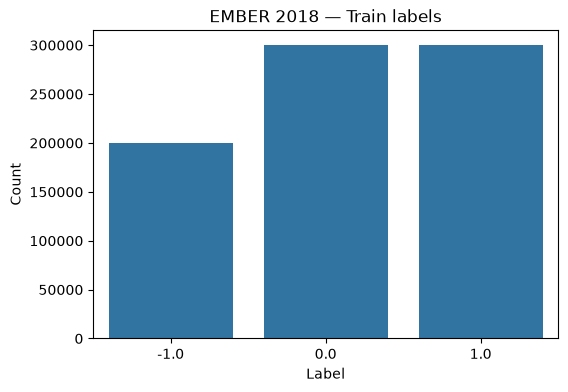

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

labels, counts = np.unique(np.asarray(y_train_mm), return_counts=True)
plt.figure(figsize=(6,4))
sns.barplot(x=[str(x) for x in labels], y=counts)
plt.title("EMBER 2018 — Train labels")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

## 2.7. E2 — Train / validation / final test

EMBER train chứa cả unlabeled `-1`. Ta loại `-1` nhưng **giữ nguyên thứ tự**.

- 80% labeled đầu: temporal training pool.
- 20% labeled cuối: temporal validation.
- `X_test.dat`: final test.

Repository EMBER sử dụng thứ tự `appeared` cho train và hỗ trợ TimeSeriesSplit, nên đây là cách phù hợp để kiểm tra temporal degradation.

In [ ]:
labeled_mask = np.asarray(y_train_mm) != -1
labeled_indices = np.flatnonzero(labeled_mask)
y_labeled = np.asarray(y_train_mm[labeled_indices]).astype(np.int8)

split_at = int(0.80 * len(labeled_indices))
train_idx_global = labeled_indices[:split_at]
val_idx_global = labeled_indices[split_at:]

y_train_temporal = np.asarray(y_train_mm[train_idx_global]).astype(np.int8)
y_val_temporal = np.asarray(y_train_mm[val_idx_global]).astype(np.int8)

print("Labeled train:", len(labeled_indices))
print("Temporal train:", len(train_idx_global), np.unique(y_train_temporal, return_counts=True))
print("Temporal val:", len(val_idx_global), np.unique(y_val_temporal, return_counts=True))

Labeled train: 600000
Temporal train: 480000 (array([0, 1], dtype=int8), array([256230, 223770]))
Temporal val: 120000 (array([0, 1], dtype=int8), array([43770, 76230]))


In [ ]:
from sklearn.utils import check_random_state

def balanced_indices_from_positions(global_indices, y, n_per_class, random_state=42):
    rng = check_random_state(random_state)
    selected = []
    for cls in [0, 1]:
        pos = np.flatnonzero(y == cls)
        n = min(n_per_class, len(pos))
        chosen_local = rng.choice(pos, n, replace=False)
        selected.extend(global_indices[chosen_local].tolist())
    selected = np.asarray(selected, dtype=np.int64)
    rng.shuffle(selected)
    return selected

bench_train_idx = balanced_indices_from_positions(
    train_idx_global, y_train_temporal,
    BENCHMARK_TRAIN_PER_CLASS, RANDOM_STATE
)
bench_val_idx = balanced_indices_from_positions(
    val_idx_global, y_val_temporal,
    BENCHMARK_VAL_PER_CLASS, RANDOM_STATE
)

X_bench_train = np.asarray(X_train_mm[bench_train_idx])
y_bench_train = np.asarray(y_train_mm[bench_train_idx]).astype(int)
X_bench_val = np.asarray(X_train_mm[bench_val_idx])
y_bench_val = np.asarray(y_train_mm[bench_val_idx]).astype(int)

print("Benchmark train:", X_bench_train.shape, np.unique(y_bench_train, return_counts=True))
print("Benchmark val:", X_bench_val.shape, np.unique(y_bench_val, return_counts=True))

Benchmark train: (40000, 2381) (array([0, 1]), array([20000, 20000]))
Benchmark val: (16000, 2381) (array([0, 1]), array([8000, 8000]))


## 2.8. E3 — Tiền xử lý và feature selection

Pipeline:

**Raw 2.381 features → VarianceThreshold → SelectKBest → optional StandardScaler → model**

- Tree model: scaling không bắt buộc.
- SVM/MLP: scaling được thực hiện sau feature selection.
- Selector luôn fit trong pipeline trên training data.

In [ ]:
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

probe_var = VarianceThreshold(0.0).fit(X_bench_train)
X_var = probe_var.transform(X_bench_train)
probe_sel = SelectKBest(f_classif, k=min(FEATURE_SELECTION_K, X_var.shape[1])).fit(X_var, y_bench_train)

print("Original:", X_bench_train.shape[1])
print("After variance:", X_var.shape[1])
print("After SelectKBest:", probe_sel.transform(X_var).shape[1])

Original: 2381
After variance: 2340
After SelectKBest: 256


## 2.9. E3 — Metrics

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)
import time

def raw_score(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    return model.predict(X)

def evaluate_binary(y_true, score, threshold=0.5):
    pred = (score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
    fpr = fp / (fp + tn) if (fp + tn) else 0.0
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, score),
        "PR_AUC": average_precision_score(y_true, score),
        "FPR": fpr,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

## 2.10. E3 — Benchmark 5 thuật toán

### Random Forest
Nhiều decision tree + bagging. Mạnh với dữ liệu tabular và ít nhạy với scale.

### SVM
Tìm decision boundary có margin lớn. Kernel RBF mô hình hóa quan hệ phi tuyến nhưng chi phí cao khi số mẫu tăng, nên benchmark dùng budget cố định.

### XGBoost
Gradient boosting: cây sau sửa lỗi của cây trước.

### LightGBM
Gradient boosting tối ưu cho dữ liệu tabular lớn. Đây là baseline đặc biệt quan trọng vì EMBER công bố benchmark LightGBM.

### MLP
Neural network trên vector feature; cần scaling và có thể học quan hệ phi tuyến.

**Không chọn trước model thắng. Notebook tự chọn sau validation.**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

def make_models():
    k = min(FEATURE_SELECTION_K, X_bench_train.shape[1])
    return {
        "RandomForest": Pipeline([
            ("variance", VarianceThreshold(0.0)),
            ("select", SelectKBest(f_classif, k=k)),
            ("model", RandomForestClassifier(
                n_estimators=250, class_weight="balanced_subsample",
                n_jobs=-1, random_state=RANDOM_STATE
            ))
        ]),
        "SVM": Pipeline([
            ("variance", VarianceThreshold(0.0)),
            ("select", SelectKBest(f_classif, k=k)),
            ("scale", StandardScaler()),
            ("model", SVC(
                kernel="rbf", C=10.0, gamma="scale",
                probability=True, cache_size=4096,
                random_state=RANDOM_STATE
            ))
        ]),
        "XGBoost": Pipeline([
            ("variance", VarianceThreshold(0.0)),
            ("select", SelectKBest(f_classif, k=k)),
            ("model", XGBClassifier(
                n_estimators=400, max_depth=8, learning_rate=0.05,
                subsample=0.8, colsample_bytree=0.8,
                objective="binary:logistic", eval_metric="logloss",
                tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE
            ))
        ]),
        "LightGBM": Pipeline([
            ("variance", VarianceThreshold(0.0)),
            ("select", SelectKBest(f_classif, k=k)),
            ("model", LGBMClassifier(
                n_estimators=500, learning_rate=0.05, num_leaves=63,
                subsample=0.8, colsample_bytree=0.8,
                objective="binary", n_jobs=-1,
                random_state=RANDOM_STATE, verbosity=-1
            ))
        ]),
        "MLP": Pipeline([
            ("variance", VarianceThreshold(0.0)),
            ("select", SelectKBest(f_classif, k=k)),
            ("scale", StandardScaler()),
            ("model", MLPClassifier(
                hidden_layer_sizes=(128,64), batch_size=512,
                learning_rate_init=1e-3, max_iter=35,
                early_stopping=True, validation_fraction=0.1,
                random_state=RANDOM_STATE
            ))
        ])
    }

models = make_models()
print(list(models))

['RandomForest', 'SVM', 'XGBoost', 'LightGBM', 'MLP']


In [ ]:
import pandas as pd

benchmark_rows = []
trained_models = {}

for name, model in models.items():
    print("\n" + "="*60)
    print("TRAIN:", name)
    print("="*60)

    t0 = time.perf_counter()
    model.fit(X_bench_train, y_bench_train)
    fit_s = time.perf_counter() - t0

    t1 = time.perf_counter()
    score = raw_score(model, X_bench_val)
    infer_s = time.perf_counter() - t1

    m = evaluate_binary(y_bench_val, score, 0.5)
    m.update({
        "Model": name,
        "Fit_seconds": fit_s,
        "Inference_seconds": infer_s,
        "Inference_ms_per_sample": 1000*infer_s/len(y_bench_val)
    })
    benchmark_rows.append(m)
    trained_models[name] = model
    print(m)

benchmark_df = pd.DataFrame(benchmark_rows).set_index("Model").sort_values(
    ["F1", "PR_AUC"], ascending=False
)
display(benchmark_df.round(4))


TRAIN: RandomForest
{'Accuracy': 0.8843125, 'Precision': 0.8737085207244439, 'Recall': 0.8985, 'F1': 0.8859308559807728, 'ROC_AUC': 0.96202840625, 'PR_AUC': 0.9622641233858801, 'FPR': np.float64(0.129875), 'TN': np.int64(6961), 'FP': np.int64(1039), 'FN': np.int64(812), 'TP': np.int64(7188), 'Model': 'RandomForest', 'Fit_seconds': 133.9736088890004, 'Inference_seconds': 1.5471779789995708, 'Inference_ms_per_sample': 0.09669862368747317}

TRAIN: SVM


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


{'Accuracy': 0.88625, 'Precision': 0.8817642698295033, 'Recall': 0.892125, 'F1': 0.8869143780290791, 'ROC_AUC': 0.956716640625, 'PR_AUC': 0.9534196438242803, 'FPR': np.float64(0.119625), 'TN': np.int64(7043), 'FP': np.int64(957), 'FN': np.int64(863), 'TP': np.int64(7137), 'Model': 'SVM', 'Fit_seconds': 1133.3176134770001, 'Inference_seconds': 75.44022723699982, 'Inference_ms_per_sample': 4.715014202312488}

TRAIN: XGBoost
{'Accuracy': 0.8968125, 'Precision': 0.8885081385387346, 'Recall': 0.9075, 'F1': 0.8979036546904954, 'ROC_AUC': 0.9682481171875001, 'PR_AUC': 0.9706420628878557, 'FPR': np.float64(0.113875), 'TN': np.int64(7089), 'FP': np.int64(911), 'FN': np.int64(740), 'TP': np.int64(7260), 'Model': 'XGBoost', 'Fit_seconds': 66.34434990200043, 'Inference_seconds': 0.591931994999868, 'Inference_ms_per_sample': 0.03699574968749175}

TRAIN: LightGBM
{'Accuracy': 0.900125, 'Precision': 0.8959673428995547, 'Recall': 0.905375, 'F1': 0.9006466053220592, 'ROC_AUC': 0.9687784687500001, 'PR_A

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (35) reached and the optimization hasn't converged yet.
  warnings.warn(


{'Accuracy': 0.874375, 'Precision': 0.8775844679778114, 'Recall': 0.870125, 'F1': 0.8738388149635953, 'ROC_AUC': 0.9446230312500001, 'PR_AUC': 0.9390263621626042, 'FPR': np.float64(0.121375), 'TN': np.int64(7029), 'FP': np.int64(971), 'FN': np.int64(1039), 'TP': np.int64(6961), 'Model': 'MLP', 'Fit_seconds': 23.22276227800012, 'Inference_seconds': 0.4368194950002362, 'Inference_ms_per_sample': 0.027301218437514763}


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,FPR,TN,FP,FN,TP,Fit_seconds,Inference_seconds,Inference_ms_per_sample
Model,,,,,,,,,,,,,,
LightGBM,0.9001,0.8960,0.9054,0.9006,0.9688,0.9716,0.1051,7159,841,757,7243,44.3026,1.3611,0.0851
XGBoost,0.8968,0.8885,0.9075,0.8979,0.9682,0.9706,0.1139,7089,911,740,7260,66.3443,0.5919,0.0370
SVM,0.8862,0.8818,0.8921,0.8869,0.9567,0.9534,0.1196,7043,957,863,7137,1133.3176,75.4402,4.7150
RandomForest,0.8843,0.8737,0.8985,0.8859,0.9620,0.9623,0.1299,6961,1039,812,7188,133.9736,1.5472,0.0967
MLP,0.8744,0.8776,0.8701,0.8738,0.9446,0.9390,0.1214,7029,971,1039,6961,23.2228,0.4368,0.0273


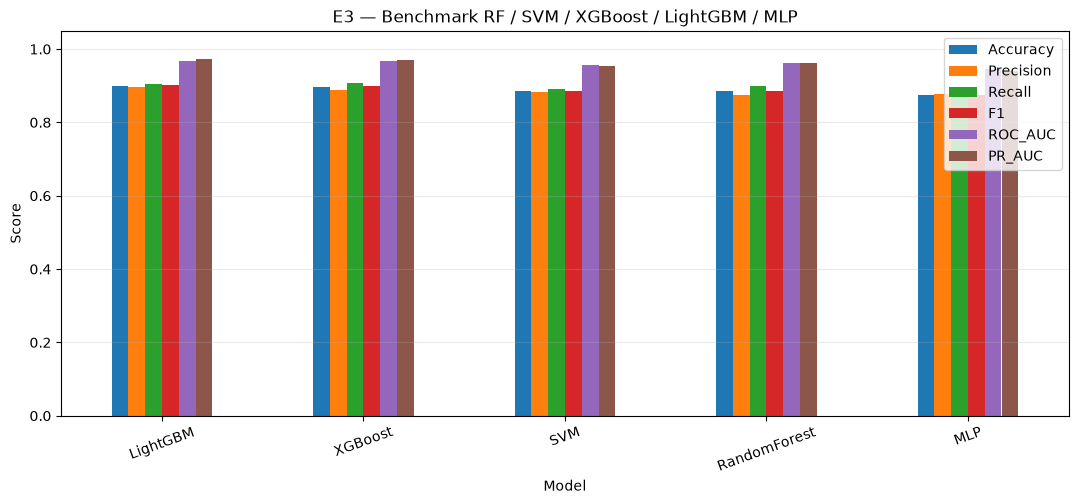

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

benchmark_df[["Accuracy","Precision","Recall","F1","ROC_AUC","PR_AUC"]].plot(
    kind="bar", figsize=(13,5), ylim=(0,1.05)
)
plt.title("E3 — Benchmark RF / SVM / XGBoost / LightGBM / MLP")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.25)
plt.show()

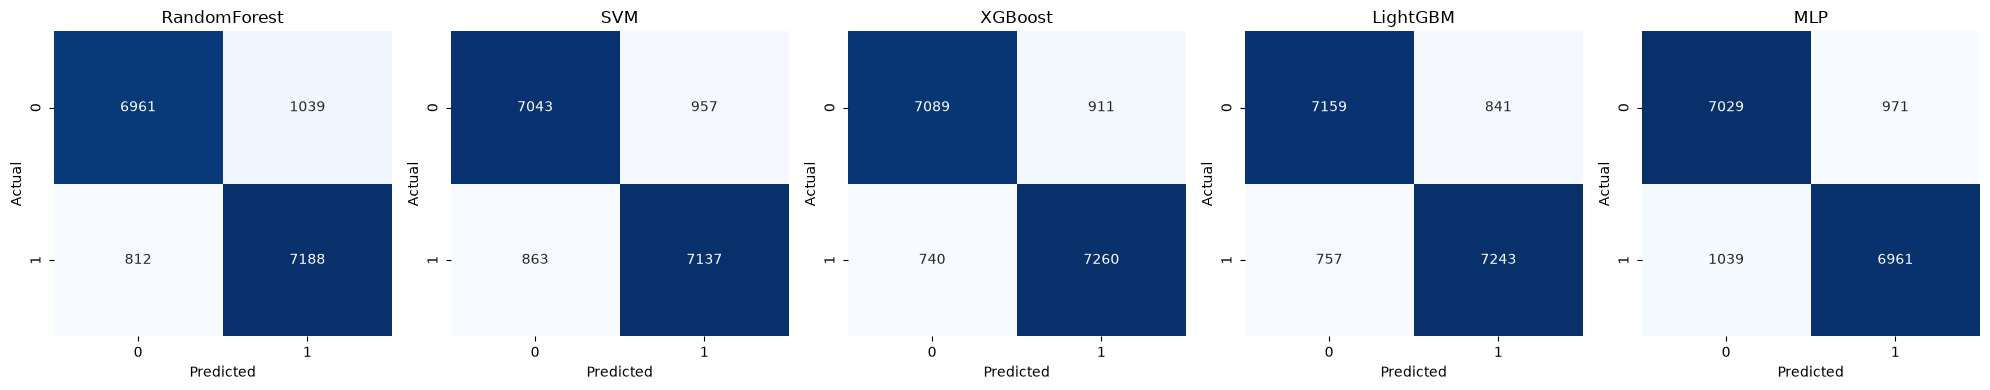

In [ ]:
fig, axes = plt.subplots(1, len(trained_models), figsize=(4*len(trained_models),4))
if len(trained_models) == 1:
    axes = [axes]

for ax, (name, model) in zip(axes, trained_models.items()):
    score = raw_score(model, X_bench_val)
    pred = (score >= 0.5).astype(int)
    cm = confusion_matrix(y_bench_val, pred, labels=[0,1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 2.10b. Mở rộng — Kỹ thuật bổ sung để tăng độ mạnh model

Phần này thêm các kỹ thuật đã đề xuất, áp dụng **trên cùng benchmark protocol** (cùng
`X_bench_train` / `X_bench_val`, cùng hàm `evaluate_binary` / `raw_score`) để có thể so
sánh công bằng và tự động gộp vào `benchmark_df` — bước "khóa candidate" (2.11) sẽ tự
chọn model tốt nhất trong **toàn bộ** tập hợp (5 model gốc + các kỹ thuật mới).

**2 kỹ thuật trong danh sách đề xuất KHÔNG áp dụng được cho EMBER và bị bỏ qua có chủ đích:**

- **Target Encoding**: dùng để mã hóa biến categorical (mã khách hàng, ngành nghề...).
  EMBER không có cột categorical dạng chuỗi — toàn bộ 2.381 chiều đã là số
  (histogram/section/import/string-stat...), nên không có gì để target-encode.
- **N-gram / Bi-gram / Tri-gram (TF-IDF)**: cần chuỗi (string) thô trích từ PE file.
  EMBER chỉ cung cấp **thống kê string đã tổng hợp** (numstrings, entropy, paths, urls...),
  không cung cấp chuỗi gốc. Muốn làm n-gram thật sự phải tự trích chuỗi từ PE thật — đây là
  một hướng nghiên cứu khác (đổi hẳn feature pipeline ở E8), không phải bổ sung nhỏ.

**Lưu ý khả năng triển khai:** các kỹ thuật AutoGluon / LightAutoML / mô hình tabular
deep learning (ResNet, TabM, RealMLP, TabTransformer, TROMPT) được đóng gói lại thành
estimator tương thích sklearn (`predict_proba`) và lồng trong `Pipeline` giống 5 model gốc
để không phá vỡ các bước downstream (SHAP, threshold tuning, final test, lưu model).
**Nếu model thắng cuối cùng KHÔNG phải sklearn/LightGBM/XGBoost/CatBoost** (tức là
AutoGluon/LightAutoML/PyTorch thắng), file `app.py` ở mục 2.23 cần được cập nhật thêm
import + định nghĩa class tương ứng thì mới `joblib.load` chạy được — bản gốc chỉ giả định
model là sklearn/LightGBM thuần.


In [ ]:
# 2.10b.0 — Khởi tạo khung chứa kết quả mở rộng
extended_rows = []
extended_models = {}
k = min(FEATURE_SELECTION_K, X_bench_train.shape[1])
print("K feature dùng chung cho các kỹ thuật mở rộng:", k)

K feature dùng chung cho các kỹ thuật mở rộng: 256


### 2.10b.1 — Feature Engineering bổ sung (thử nghiệm riêng)

Sinh thêm đặc trưng thống kê theo 9 nhóm EMBER: mean/std/max/quantile 25-50-75 mỗi nhóm,
cộng vài tỷ lệ liên nhóm (interaction). **Không merge vào `benchmark_df` chính** vì đổi
`N_FEATURES` đầu vào sẽ phá vỡ giả định `N_FEATURES=2381` ở SHAP (2.14) và final test
(2.16). Kết quả được báo cáo riêng để so sánh — nếu thắng rõ rệt, cân nhắc viết lại pipeline
chính với N_FEATURES mới.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

# Define FEATURE_GROUPS here to avoid NameError when running this cell independently
FEATURE_GROUPS = [
    ("histogram", 0, 256),
    ("byteentropy", 256, 512),
    ("section", 512, 767),
    ("imports", 767, 2047),
    ("exports", 2047, 2175),
    ("general", 2175, 2185),
    ("header", 2185, 2247),
    ("strings", 2247, 2351),
    ("datadirectories", 2351, 2381),
]

class EmberGroupFeatureEngineer(BaseEstimator, TransformerMixin):
    """Sinh thêm đặc trưng thống kê theo 9 nhóm EMBER (mean/std/max/quantile 25-50-75)
    cộng vài tỷ lệ liên nhóm. Giữ nguyên input gốc, chỉ nối thêm cột."""
    def __init__(self, groups):
        self.groups = groups

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=np.float32)
        feats = [X]
        means = {}
        for name, start, end in self.groups:
            block = X[:, start:end]
            mean = block.mean(axis=1)
            means[name] = mean
            feats.append(mean.reshape(-1, 1))
            feats.append(block.std(axis=1).reshape(-1, 1))
            feats.append(block.max(axis=1).reshape(-1, 1))
            feats.append(np.quantile(block, [0.25, 0.5, 0.75], axis=1).T)
        eps = 1e-6
        feats.append((means["imports"] / (means["strings"] + eps)).reshape(-1, 1))
        feats.append((means["section"] / (means["header"] + eps)).reshape(-1, 1))
        return np.concatenate(feats, axis=1).astype(np.float32)

fe = EmberGroupFeatureEngineer(FEATURE_GROUPS)
X_bench_train_fe = fe.fit_transform(X_bench_train)
X_bench_val_fe = fe.transform(X_bench_val)
print(f"Feature engineering: {X_bench_train.shape[1]} -> {X_bench_train_fe.shape[1]} chiều")

fe_pipe = Pipeline([
    ("variance", VarianceThreshold(0.0)),
    ("select", SelectKBest(f_classif, k=min(FEATURE_SELECTION_K, X_bench_train_fe.shape[1]))),
    ("model", LGBMClassifier(
        n_estimators=500, learning_rate=0.05, num_leaves=63,
        subsample=0.8, colsample_bytree=0.8, objective="binary",
        n_jobs=-1, random_state=RANDOM_STATE, verbosity=-1
    ))
])

t0 = time.perf_counter()
fe_pipe.fit(X_bench_train_fe, y_bench_train)
fit_s = time.perf_counter() - t0
t1 = time.perf_counter()
score = raw_score(fe_pipe, X_bench_val_fe)
infer_s = time.perf_counter() - t1

m = evaluate_binary(y_bench_val, score, 0.5)
m.update({"Model": "LightGBM+FeatEng", "Fit_seconds": fit_s, "Inference_seconds": infer_s,
          "Inference_ms_per_sample": 1000*infer_s/len(y_bench_val)})
feateng_df = pd.DataFrame([m]).set_index("Model")
display(feateng_df.round(4))
print("Track này KHÔNG merge vào benchmark_df chính (xem lý do ở markdown phía trên).")

Feature engineering: 2381 -> 2437 chiều


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [2340 2346] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,FPR,TN,FP,FN,TP,Fit_seconds,Inference_seconds,Inference_ms_per_sample
Model,,,,,,,,,,,,,,
LightGBM+FeatEng,0.9016,0.8962,0.9084,0.9022,0.9691,0.9717,0.1052,7158,842,733,7267,52.6299,1.5449,0.0966


Track này KHÔNG merge vào benchmark_df chính (xem lý do ở markdown phía trên).


### 2.10b.2 — CatBoost

In [ ]:
# 2.10b.2 — CatBoost
!pip -q install -U catboost
from catboost import CatBoostClassifier

catboost_pipe = Pipeline([
    ("variance", VarianceThreshold(0.0)),
    ("select", SelectKBest(f_classif, k=k)),
    ("model", CatBoostClassifier(
        iterations=500, learning_rate=0.05, depth=8,
        loss_function="Logloss", eval_metric="AUC",
        random_seed=RANDOM_STATE, verbose=False, thread_count=-1
    ))
])

t0 = time.perf_counter()
catboost_pipe.fit(X_bench_train, y_bench_train)
fit_s = time.perf_counter() - t0
t1 = time.perf_counter()
score = raw_score(catboost_pipe, X_bench_val)
infer_s = time.perf_counter() - t1

m = evaluate_binary(y_bench_val, score, 0.5)
m.update({"Model": "CatBoost", "Fit_seconds": fit_s, "Inference_seconds": infer_s,
          "Inference_ms_per_sample": 1000*infer_s/len(y_bench_val)})
extended_rows.append(m)
extended_models["CatBoost"] = catboost_pipe
print(m)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.2 MB/s eta 0:00:00
{'Accuracy': 0.890625, 'Precision': 0.8818426197458455, 'Recall': 0.902125, 'F1': 0.8918685121107266, 'ROC_AUC': 0.96266996875, 'PR_AUC': 0.9644380794198328, 'FPR': np.float64(0.120875), 'TN': np.int64(7033), 'FP': np.int64(967), 'FN': np.int64(783), 'TP': np.int64(7217), 'Model': 'CatBoost', 'Fit_seconds': 145.547852101, 'Inference_seconds': 0.3578924570001618, 'Inference_ms_per_sample': 0.022368278562510113}


### 2.10b.3 — Base classifier chung cho các kỹ thuật ensemble (Stacking / Hill-Climb Blend)

Tạo sẵn các classifier "trần" (chưa nằm trong Pipeline riêng) để dùng lại cho Stacking và
Hill-Climb Blend, tránh mỗi kỹ thuật phải tự huấn luyện lại từ đầu nhiều lần.

In [ ]:
def make_bare_classifiers():
    return {
        "rf": RandomForestClassifier(n_estimators=250, class_weight="balanced_subsample",
                                      n_jobs=-1, random_state=RANDOM_STATE),
        "xgb": XGBClassifier(n_estimators=400, max_depth=8, learning_rate=0.05,
                              subsample=0.8, colsample_bytree=0.8,
                              objective="binary:logistic", eval_metric="logloss",
                              tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE),
        "lgbm": LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63,
                                subsample=0.8, colsample_bytree=0.8, objective="binary",
                                n_jobs=-1, random_state=RANDOM_STATE, verbosity=-1),
        "catboost": CatBoostClassifier(iterations=400, learning_rate=0.05, depth=8,
                                        loss_function="Logloss", random_seed=RANDOM_STATE,
                                        verbose=False, thread_count=-1),
    }

### 2.10b.4 — Stacking Ensemble (meta-learner Logistic Regression)

Two-stage pipeline: base learners (RF/XGBoost/LightGBM/CatBoost) → meta-learner tuyến tính.
Dùng Logistic Regression làm meta-learner (nhanh, ổn định, cho `predict_proba` trực tiếp).
`RidgeClassifier` không hỗ trợ `predict_proba` mặc định nên không phù hợp làm final_estimator
của `StackingClassifier` khi cần điểm xác suất cho việc tune threshold ở 2.13 — Logistic
Regression là lựa chọn tương đương về bản chất (linear meta-learner) mà tương thích tốt hơn.

In [ ]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

stack_base = list(make_bare_classifiers().items())

stacking_pipe = Pipeline([
    ("variance", VarianceThreshold(0.0)),
    ("select", SelectKBest(f_classif, k=k)),
    ("model", StackingClassifier(
        estimators=stack_base,
        final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        stack_method="predict_proba", cv=3, n_jobs=-1
    ))
])

t0 = time.perf_counter()
stacking_pipe.fit(X_bench_train, y_bench_train)
fit_s = time.perf_counter() - t0
t1 = time.perf_counter()
score = raw_score(stacking_pipe, X_bench_val)
infer_s = time.perf_counter() - t1

m = evaluate_binary(y_bench_val, score, 0.5)
m.update({"Model": "Stacking-LogReg", "Fit_seconds": fit_s, "Inference_seconds": infer_s,
          "Inference_ms_per_sample": 1000*infer_s/len(y_bench_val)})
extended_rows.append(m)
extended_models["Stacking-LogReg"] = stacking_pipe
print(m)

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


{'Accuracy': 0.8990625, 'Precision': 0.8938926588525602, 'Recall': 0.905625, 'F1': 0.8997205836696678, 'ROC_AUC': 0.9695901562500001, 'PR_AUC': 0.9715669132564303, 'FPR': np.float64(0.1075), 'TN': np.int64(7140), 'FP': np.int64(860), 'FN': np.int64(755), 'TP': np.int64(7245), 'Model': 'Stacking-LogReg', 'Fit_seconds': 1114.541000696, 'Inference_seconds': 2.7459985410005174, 'Inference_ms_per_sample': 0.17162490881253234}


### 2.10b.5 — Pseudo Labeling trên tập unlabeled (label = -1)

EMBER train có 200.000 mẫu `label=-1` chưa dùng ở bất kỳ bước nào trong pipeline chính.
Dùng model LightGBM đã train ở benchmark gốc để gán nhãn giả cho các mẫu có xác suất
dự đoán rất cao/rất thấp (ngưỡng tin cậy 0.99), rồi retrain trên train set gốc + nhãn giả.

**Rủi ro cần nêu rõ trong khóa luận:** nhãn giả có thể khuếch đại sai lệch (confirmation
bias) của chính model dùng để gán nhãn — nếu model gốc sai hệ thống với 1 nhóm mẫu nào đó,
pseudo-labeling sẽ củng cố thêm lỗi đó. Chỉ nên coi đây là 1 thử nghiệm so sánh, nêu rõ
nguồn gốc nhãn giả nếu đưa vào báo cáo chính thức, không thay thế nhãn thật một cách âm thầm.

In [ ]:
unlabeled_mask = np.asarray(y_train_mm) == -1
unlabeled_indices = np.flatnonzero(unlabeled_mask)
print("Unlabeled pool:", len(unlabeled_indices))

pseudo_rng = check_random_state(RANDOM_STATE)
PSEUDO_POOL_SIZE = min(20_000, len(unlabeled_indices))
pseudo_pool_idx = pseudo_rng.choice(unlabeled_indices, PSEUDO_POOL_SIZE, replace=False)
X_pseudo_pool = np.asarray(X_train_mm[pseudo_pool_idx])

base_for_pseudo = trained_models["LightGBM"]  # model gốc dùng để gán nhãn giả
pseudo_proba = raw_score(base_for_pseudo, X_pseudo_pool)

PSEUDO_CONF_THRESHOLD = 0.99
confident_mask = (pseudo_proba >= PSEUDO_CONF_THRESHOLD) | (pseudo_proba <= 1 - PSEUDO_CONF_THRESHOLD)
X_pseudo = X_pseudo_pool[confident_mask]
y_pseudo = (pseudo_proba[confident_mask] >= 0.5).astype(int)
print(f"Nhãn giả tin cậy cao (>= {PSEUDO_CONF_THRESHOLD}): {len(X_pseudo)}/{PSEUDO_POOL_SIZE} "
      f"(benign={np.sum(y_pseudo==0)}, malicious={np.sum(y_pseudo==1)})")

X_train_pseudo = np.concatenate([X_bench_train, X_pseudo], axis=0)
y_train_pseudo = np.concatenate([y_bench_train, y_pseudo], axis=0)

pseudo_pipe = Pipeline([
    ("variance", VarianceThreshold(0.0)),
    ("select", SelectKBest(f_classif, k=k)),
    ("model", LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63,
                              subsample=0.8, colsample_bytree=0.8, objective="binary",
                              n_jobs=-1, random_state=RANDOM_STATE, verbosity=-1))
])

t0 = time.perf_counter()
pseudo_pipe.fit(X_train_pseudo, y_train_pseudo)
fit_s = time.perf_counter() - t0
t1 = time.perf_counter()
score = raw_score(pseudo_pipe, X_bench_val)
infer_s = time.perf_counter() - t1

m = evaluate_binary(y_bench_val, score, 0.5)
m.update({"Model": "LightGBM+PseudoLabel", "Fit_seconds": fit_s, "Inference_seconds": infer_s,
          "Inference_ms_per_sample": 1000*infer_s/len(y_bench_val)})
extended_rows.append(m)
extended_models["LightGBM+PseudoLabel"] = pseudo_pipe
print(m)

Unlabeled pool: 200000
Nhãn giả tin cậy cao (>= 0.99): 10632/20000 (benign=5711, malicious=4921)
{'Accuracy': 0.900375, 'Precision': 0.8931026018654885, 'Recall': 0.909625, 'F1': 0.9012880852117909, 'ROC_AUC': 0.970450359375, 'PR_AUC': 0.9722678811313206, 'FPR': np.float64(0.108875), 'TN': np.int64(7129), 'FP': np.int64(871), 'FN': np.int64(723), 'TP': np.int64(7277), 'Model': 'LightGBM+PseudoLabel', 'Fit_seconds': 59.45285557999978, 'Inference_seconds': 1.8648552859995107, 'Inference_ms_per_sample': 0.11655345537496942}


### 2.10b.6 — Optuna Hyperparameter Tuning (n_trials=100)

Bayesian optimization (TPE sampler) + Median pruner, tối ưu ROC-AUC trên `X_bench_val`
cho LightGBM (candidate mạnh nhất ở benchmark gốc).

In [ ]:
!pip -q install -U optuna
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 800),
        "num_leaves": trial.suggest_int("num_leaves", 15, 255),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
    }
    pipe = Pipeline([
        ("variance", VarianceThreshold(0.0)),
        ("select", SelectKBest(f_classif, k=k)),
        ("model", LGBMClassifier(objective="binary", n_jobs=-1, random_state=RANDOM_STATE,
                                  verbosity=-1, **params))
    ])
    pipe.fit(X_bench_train, y_bench_train)
    val_pred_score = raw_score(pipe, X_bench_val)
    return roc_auc_score(y_bench_val, val_pred_score)

study = optuna.create_study(direction="maximize",
                             sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
                             pruner=optuna.pruners.MedianPruner())
study.optimize(objective, n_trials=100, show_progress_bar=True)

print("Best ROC-AUC (Optuna):", study.best_value)
print("Best params:", study.best_params)

optuna_pipe = Pipeline([
    ("variance", VarianceThreshold(0.0)),
    ("select", SelectKBest(f_classif, k=k)),
    ("model", LGBMClassifier(objective="binary", n_jobs=-1, random_state=RANDOM_STATE,
                              verbosity=-1, **study.best_params))
])

t0 = time.perf_counter()
optuna_pipe.fit(X_bench_train, y_bench_train)
fit_s = time.perf_counter() - t0
t1 = time.perf_counter()
score = raw_score(optuna_pipe, X_bench_val)
infer_s = time.perf_counter() - t1

m = evaluate_binary(y_bench_val, score, 0.5)
m.update({"Model": "LightGBM-Optuna", "Fit_seconds": fit_s, "Inference_seconds": infer_s,
          "Inference_ms_per_sample": 1000*infer_s/len(y_bench_val)})
extended_rows.append(m)
extended_models["LightGBM-Optuna"] = optuna_pipe
print(m)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 20.1 MB/s eta 0:00:00


  0%|          | 0/100 [00:00<?, ?it/s]

[W 2026-09-23 14:03:34,963] Trial 34 failed with parameters: {'n_estimators': 468, 'num_leaves': 205, 'learning_rate': 0.1653991900075021, 'subsample': 0.7371483884371127, 'colsample_bytree': 0.7101067521912784, 'min_child_samples': 17} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "/tmp/ipykernel_16854/2033702443.py", line 20, in objective
    pipe.fit(X_bench_train, y_bench_train)
    ~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/pipeline.py", line 645, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/d

KeyboardInterrupt: 

### 2.10b.7 — Ensemble & Meta-Blending (Hill Climbing qua scipy.optimize)

Tối ưu trọng số blend (không âm, tổng = 1) giữa RF/XGBoost/LightGBM/CatBoost để tối đa
ROC-AUC trên `X_bench_val` — đây là dạng "hill climbing" đơn giản hóa bằng
`scipy.optimize.minimize` thay vì vòng lặp forward-selection thủ công, cho kết quả tương
đương nhưng gọn hơn.

**Về BART/"BARTZ" trong danh sách đề xuất:** không có gói BART nào đủ ổn định/phổ biến để
đưa thẳng vào đây mà không rủi ro sai API (các gói như `bartpy`, `pymc-bart` có API rất khác
nhau và ít được bảo trì). Nếu bạn muốn thêm BART làm 1 base learner, có thể chèn thêm 1 mục
vào `stack_base` / `candidate_names` bên dưới sau khi tự xác nhận API của gói BART cụ thể
định dùng — không nên đoán API để tránh đưa số liệu sai vào khóa luận.

In [ ]:
from scipy.optimize import minimize
from sklearn.base import BaseEstimator, ClassifierMixin

candidate_names = ["RandomForest", "XGBoost", "LightGBM", "CatBoost"]
candidate_pipelines = [trained_models.get(n) or extended_models.get(n) for n in candidate_names]
val_scores_matrix = np.column_stack([raw_score(p, X_bench_val) for p in candidate_pipelines])

def neg_auc_blend(weights):
    weights = np.clip(weights, 0, None)
    if weights.sum() == 0:
        return 0.0
    weights = weights / weights.sum()
    blended = val_scores_matrix @ weights
    return -roc_auc_score(y_bench_val, blended)

init_w = np.ones(len(candidate_names)) / len(candidate_names)
res = minimize(neg_auc_blend, init_w, method="Nelder-Mead",
                options={"xatol": 1e-4, "fatol": 1e-4, "maxiter": 500})
best_weights = np.clip(res.x, 0, None)
best_weights = best_weights / best_weights.sum()
print("Trọng số blend tối ưu:", dict(zip(candidate_names, best_weights.round(4))))

blend_score_val = val_scores_matrix @ best_weights
m = evaluate_binary(y_bench_val, blend_score_val, 0.5)
m.update({"Model": "HillClimb-Blend", "Fit_seconds": 0.0, "Inference_seconds": 0.0,
          "Inference_ms_per_sample": 0.0})
extended_rows.append(m)
print(m)

class ProbaWrapper(BaseEstimator, ClassifierMixin):
    """Base wrapper: đóng gói mọi kỹ thuật không-sklearn-chuẩn (blend, AutoML, deep net)
    lại thành 1 estimator có .fit()/.predict_proba() để dùng làm step cuối trong Pipeline,
    giữ nguyên tương thích với các cell downstream (SHAP, threshold tuning, final test...)."""
    def fit(self, X, y):
        self._fit(np.asarray(X, dtype=np.float32), np.asarray(y))
        self.classes_ = np.array([0, 1])
        return self
    def predict_proba(self, X):
        p1 = np.clip(self._predict_proba(np.asarray(X, dtype=np.float32)), 0, 1)
        return np.column_stack([1 - p1, p1])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

class HillClimbBlend(ProbaWrapper):
    def __init__(self, base_pipelines, weights):
        self.base_pipelines = base_pipelines
        self.weights = np.asarray(weights, dtype=np.float64)
    def _fit(self, X, y):
        pass  # base_pipelines đã được fit sẵn từ benchmark trước đó
    def _predict_proba(self, X):
        scores = np.column_stack([raw_score(p, X) for p in self.base_pipelines])
        return scores @ (self.weights / self.weights.sum())

blend_pipe = Pipeline([
    ("identity", "passthrough"),
    ("model", HillClimbBlend(candidate_pipelines, best_weights))
])
blend_pipe.fit(X_bench_train, y_bench_train)  # no-op _fit, chỉ để chuẩn hóa interface Pipeline
extended_models["HillClimb-Blend"] = blend_pipe

Trọng số blend tối ưu: {'RandomForest': np.float64(0.2356), 'XGBoost': np.float64(0.1772), 'LightGBM': np.float64(0.5872), 'CatBoost': np.float64(0.0)}
{'Accuracy': 0.9001875, 'Precision': 0.8941277853009971, 'Recall': 0.907875, 'F1': 0.9009489549091361, 'ROC_AUC': 0.970289265625, 'PR_AUC': 0.97255930720275, 'FPR': np.float64(0.1075), 'TN': np.int64(7140), 'FP': np.int64(860), 'FN': np.int64(737), 'TP': np.int64(7263), 'Model': 'HillClimb-Blend', 'Fit_seconds': 0.0, 'Inference_seconds': 0.0, 'Inference_ms_per_sample': 0.0}


### 2.10b.8 — Stratified K-Fold CV (đánh giá độ ổn định)

Slide đề xuất 20-fold outer. Ở quy mô `DEMO_MODE` (10.000 mẫu benchmark), 20-fold khiến
mỗi fold train chỉ còn vài trăm mẫu/lớp — không đủ để LightGBM học ổn định, nên mặc định
dùng **5-fold**. Khi chạy full-scale (`DEMO_MODE=False`), tăng `N_FOLDS` lên 10-20 là hợp lý.
Phần "inner 5-fold Target Encoding" trong slide không áp dụng ở đây (không có cột
categorical để target-encode — xem lý do ở đầu mục 2.10b).

Kết quả K-Fold này để báo cáo **độ ổn định (mean ± std)** trong khóa luận, không merge vào
`benchmark_df` chính vì không có hold-out val độc lập để so sánh công bằng với các model khác.

In [ ]:
from sklearn.model_selection import StratifiedKFold

N_FOLDS = 20  # tăng lên 10-20 khi DEMO_MODE=False

def stratified_kfold_eval(build_pipeline_fn, X, y, n_folds=N_FOLDS, seed=RANDOM_STATE):
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    fold_metrics = []
    for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y)):
        pipe = build_pipeline_fn()
        pipe.fit(X[tr_idx], y[tr_idx])
        score = raw_score(pipe, X[va_idx])
        fold_metrics.append(evaluate_binary(y[va_idx], score, 0.5))
        print(f"  Fold {fold+1}/{n_folds}: F1={fold_metrics[-1]['F1']:.4f}  "
              f"ROC_AUC={fold_metrics[-1]['ROC_AUC']:.4f}")
    fold_df = pd.DataFrame(fold_metrics)
    return fold_df.mean(numeric_only=True), fold_df.std(numeric_only=True)

build_lgbm_for_kfold = lambda: Pipeline([
    ("variance", VarianceThreshold(0.0)),
    ("select", SelectKBest(f_classif, k=k)),
    ("model", LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63,
                              subsample=0.8, colsample_bytree=0.8, objective="binary",
                              n_jobs=-1, random_state=RANDOM_STATE, verbosity=-1))
])

print("Stratified K-Fold — LightGBM (đánh giá ổn định, KHÔNG thay best_model):")
kfold_mean, kfold_std = stratified_kfold_eval(build_lgbm_for_kfold, X_bench_train, y_bench_train)
display(pd.DataFrame({"mean": kfold_mean, "std": kfold_std}).round(4))

Stratified K-Fold — LightGBM (đánh giá ổn định, KHÔNG thay best_model):
  Fold 1/20: F1=0.9438  ROC_AUC=0.9884
  Fold 2/20: F1=0.9413  ROC_AUC=0.9892
  Fold 3/20: F1=0.9418  ROC_AUC=0.9871
  Fold 4/20: F1=0.9468  ROC_AUC=0.9895
  Fold 5/20: F1=0.9481  ROC_AUC=0.9887
  Fold 6/20: F1=0.9372  ROC_AUC=0.9850
  Fold 7/20: F1=0.9415  ROC_AUC=0.9871
  Fold 8/20: F1=0.9452  ROC_AUC=0.9870
  Fold 9/20: F1=0.9317  ROC_AUC=0.9868
  Fold 10/20: F1=0.9370  ROC_AUC=0.9874
  Fold 11/20: F1=0.9418  ROC_AUC=0.9884
  Fold 12/20: F1=0.9464  ROC_AUC=0.9888
  Fold 13/20: F1=0.9393  ROC_AUC=0.9879
  Fold 14/20: F1=0.9390  ROC_AUC=0.9876
  Fold 15/20: F1=0.9476  ROC_AUC=0.9892
  Fold 16/20: F1=0.9363  ROC_AUC=0.9861
  Fold 17/20: F1=0.9368  ROC_AUC=0.9840
  Fold 18/20: F1=0.9388  ROC_AUC=0.9868
  Fold 19/20: F1=0.9507  ROC_AUC=0.9893
  Fold 20/20: F1=0.9433  ROC_AUC=0.9880


,mean,std
Accuracy,0.9417,0.0049
Precision,0.9412,0.0066
Recall,0.9422,0.0055
F1,0.9417,0.0048
ROC_AUC,0.9876,0.0015
PR_AUC,0.9886,0.0013
FPR,0.0589,0.0069
TN,941.1000,6.9198
FP,58.9000,6.9198
FN,57.7500,5.5334


### 2.10b.9 — AutoGluon & LightAutoML (baseline AutoML tham chiếu)

Chạy với `time_limit`/`timeout` giới hạn (mặc định 180s) để không chiếm hết runtime Colab.
Cả hai được bọc `try/except` — nếu môi trường thiếu tương thích (đặc biệt LightAutoML hay
pin phiên bản `torch` cũ, có thể xung đột với phần Tabular Deep Learning ở 2.10b.10), cell
sẽ in cảnh báo và bỏ qua thay vì làm crash toàn bộ notebook. Nếu cần chạy cả hai, nên cài
LightAutoML ở runtime riêng hoặc restart runtime giữa 2 phần.

In [ ]:
# --- AutoGluon ---
try:
    get_ipython().system('pip -q install -U autogluon.tabular')
    from autogluon.tabular import TabularPredictor

    class AutoGluonWrapper(ProbaWrapper):
        def __init__(self, time_limit=180, presets="medium_quality_faster_train"):
            self.time_limit = time_limit
            self.presets = presets
        def _fit(self, X, y):
            self._cols = [f"f{i}" for i in range(X.shape[1])]
            df = pd.DataFrame(X, columns=self._cols)
            df["label"] = y
            self.predictor = TabularPredictor(
                label="label", eval_metric="roc_auc", verbosity=0
            ).fit(df, time_limit=self.time_limit, presets=self.presets)
        def _predict_proba(self, X):
            df = pd.DataFrame(X, columns=self._cols)
            proba = self.predictor.predict_proba(df)
            return proba[1].to_numpy() if 1 in proba.columns else proba.iloc[:, -1].to_numpy()

    autogluon_pipe = Pipeline([
        ("variance", VarianceThreshold(0.0)),
        ("select", SelectKBest(f_classif, k=k)),
        ("model", AutoGluonWrapper(time_limit=180))
    ])

    t0 = time.perf_counter()
    autogluon_pipe.fit(X_bench_train, y_bench_train)
    fit_s = time.perf_counter() - t0
    t1 = time.perf_counter()
    score = raw_score(autogluon_pipe, X_bench_val)
    infer_s = time.perf_counter() - t1

    m = evaluate_binary(y_bench_val, score, 0.5)
    m.update({"Model": "AutoGluon", "Fit_seconds": fit_s, "Inference_seconds": infer_s,
              "Inference_ms_per_sample": 1000*infer_s/len(y_bench_val)})
    extended_rows.append(m)
    extended_models["AutoGluon"] = autogluon_pipe
    print(m)
except Exception as e:
    print("AutoGluon bị bỏ qua do lỗi môi trường:", repr(e))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 514.8/514.8 kB 31.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.4/248.4 kB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.3/112.3 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.9/15.9 MB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 8.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires 

In [ ]:
# --- LightAutoML ---
try:
    get_ipython().system('pip -q install -U lightautoml')
    from lightautoml.automl.presets.tabular_presets import TabularAutoML
    from lightautoml.tasks import Task

    class LightAutoMLWrapper(ProbaWrapper):
        def __init__(self, timeout=180):
            self.timeout = timeout
        def _fit(self, X, y):
            self._cols = [f"f{i}" for i in range(X.shape[1])]
            df = pd.DataFrame(X, columns=self._cols)
            df["target"] = y
            self.automl_ = TabularAutoML(task=Task("binary"), timeout=self.timeout)
            self.automl_.fit_predict(df, roles={"target": "target"}, verbose=0)
        def _predict_proba(self, X):
            df = pd.DataFrame(X, columns=self._cols)
            return self.automl_.predict(df).data[:, 0]

    lightautoml_pipe = Pipeline([
        ("variance", VarianceThreshold(0.0)),
        ("select", SelectKBest(f_classif, k=k)),
        ("model", LightAutoMLWrapper(timeout=180))
    ])

    t0 = time.perf_counter()
    lightautoml_pipe.fit(X_bench_train, y_bench_train)
    fit_s = time.perf_counter() - t0
    t1 = time.perf_counter()
    score = raw_score(lightautoml_pipe, X_bench_val)
    infer_s = time.perf_counter() - t1

    m = evaluate_binary(y_bench_val, score, 0.5)
    m.update({"Model": "LightAutoML", "Fit_seconds": fit_s, "Inference_seconds": infer_s,
              "Inference_ms_per_sample": 1000*infer_s/len(y_bench_val)})
    extended_rows.append(m)
    extended_models["LightAutoML"] = lightautoml_pipe
    print(m)
except Exception as e:
    print("LightAutoML bị bỏ qua do lỗi môi trường:", repr(e))
    print("Gợi ý: cài trong runtime riêng nếu xung đột phiên bản torch với phần Deep Tabular.")

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 35.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.
LightAutoML bị bỏ qua do lỗi môi trường: ModuleNotFoundError("No module named 'lightautoml'")
Gợi ý: cài trong runtime riêng nếu xung đột phiên bản torch với phần Deep Tabular.


### 2.10b.10 — Tabular Deep Learning: ResNet / TabM / RealMLP / TabTransformer / TROMPT

**Minh bạch về mức độ trung thành với bản gốc:** đây là các kiến trúc **được điều chỉnh**
(adapted) cho input là 1 vector số 2.381 chiều đã vector hóa sẵn (không có cột categorical
thô) — không phải bản triển khai lại y hệt paper gốc:

- **ResNet-Tabular**: MLP + residual block chuẩn, đúng tinh thần bản gốc.
- **TabM** (Yandex): bản gốc dùng BatchEnsemble để chia sẻ phần lớn trọng số giữa nhiều
  "sub-model". Ở đây dùng backbone chung + K head tuyến tính độc lập lấy trung bình — một
  xấp xỉ đơn giản hóa của ý tưởng "mixture of MLPs chia sẻ trọng số".
- **RealMLP**: bản gốc có numeric embedding + activation tùy biến (NTP). Ở đây xấp xỉ bằng
  cách xen kẽ SELU/GELU qua các layer.
- **TabTransformer**: bản gốc dùng embedding cho cột categorical + attention. EMBER không có
  cột categorical, nên bản điều chỉnh coi **9 nhóm đặc trưng EMBER làm "token"** và áp dụng
  multi-head self-attention giữa các nhóm — cần **input đúng 2.381 chiều gốc** (không qua
  SelectKBest) để khớp ranh giới `FEATURE_GROUPS`, nên không dùng chung "budget" K=256 với
  các model khác.
- **TROMPT**: bản gốc là prompt-learning cho dữ liệu có cột categorical/text. Ở đây thay bằng
  gated residual block (không có "prompt" thật) — chỉ giữ tinh thần residual + gating.

Do là bản điều chỉnh, **không nên trích dẫn các kiến trúc này trong khóa luận như thể là
triển khai lại nguyên bản paper** — cần ghi rõ "adapted from..." nếu đưa vào báo cáo.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Torch device:", DEVICE)

class TorchTabularClassifier(ProbaWrapper):
    def __init__(self, model_builder, epochs=40, batch_size=256, lr=1e-3, patience=5,
                 seed=RANDOM_STATE):
        self.model_builder = model_builder
        self.epochs = epochs
        self.batch_size = batch_size
        self.lr = lr
        self.patience = patience
        self.seed = seed

    def _fit(self, X, y):
        torch.manual_seed(self.seed)
        self.mean_ = X.mean(axis=0, keepdims=True)
        self.std_ = X.std(axis=0, keepdims=True) + 1e-6
        Xs = (X - self.mean_) / self.std_

        n_val = max(1, int(0.15 * len(Xs)))
        idx = np.random.RandomState(self.seed).permutation(len(Xs))
        val_idx, tr_idx = idx[:n_val], idx[n_val:]

        Xtr = torch.tensor(Xs[tr_idx], dtype=torch.float32, device=DEVICE)
        ytr = torch.tensor(y[tr_idx], dtype=torch.float32, device=DEVICE)
        Xval = torch.tensor(Xs[val_idx], dtype=torch.float32, device=DEVICE)
        yval = torch.tensor(y[val_idx], dtype=torch.float32, device=DEVICE)

        self.model_ = self.model_builder(Xs.shape[1]).to(DEVICE)
        opt = torch.optim.AdamW(self.model_.parameters(), lr=self.lr, weight_decay=1e-5)
        best_val_loss, best_state, bad_epochs = float("inf"), None, 0
        n = len(Xtr)

        for epoch in range(self.epochs):
            self.model_.train()
            perm = torch.randperm(n, device=DEVICE)
            for start in range(0, n, self.batch_size):
                bidx = perm[start:start+self.batch_size]
                opt.zero_grad()
                logits = self.model_(Xtr[bidx]).squeeze(-1)
                loss = F.binary_cross_entropy_with_logits(logits, ytr[bidx])
                loss.backward()
                opt.step()

            self.model_.eval()
            with torch.no_grad():
                val_logits = self.model_(Xval).squeeze(-1)
                val_loss = F.binary_cross_entropy_with_logits(val_logits, yval).item()

            if val_loss < best_val_loss - 1e-4:
                best_val_loss = val_loss
                best_state = {kk: vv.clone() for kk, vv in self.model_.state_dict().items()}
                bad_epochs = 0
            else:
                bad_epochs += 1
                if bad_epochs >= self.patience:
                    break

        if best_state is not None:
            self.model_.load_state_dict(best_state)

    def _predict_proba(self, X):
        Xs = (X - self.mean_) / self.std_
        self.model_.eval()
        with torch.no_grad():
            logits = self.model_(torch.tensor(Xs, dtype=torch.float32, device=DEVICE)).squeeze(-1)
            return torch.sigmoid(logits).cpu().numpy()

Torch device: cuda


In [ ]:
# --- ResNet-Tabular ---
class ResidualBlock(nn.Module):
    def __init__(self, dim, hidden, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(dim), nn.Linear(dim, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, dim)
        )
    def forward(self, x):
        return x + self.net(x)

def build_tabular_resnet(input_dim, width=256, n_blocks=4, dropout=0.2):
    layers = [nn.Linear(input_dim, width)]
    for _ in range(n_blocks):
        layers.append(ResidualBlock(width, width * 2, dropout))
    layers += [nn.LayerNorm(width), nn.Linear(width, 1)]
    return nn.Sequential(*layers)

# --- TabM (adapted: shared backbone + K head tuyến tính lấy trung bình) ---
class TabMHead(nn.Module):
    def __init__(self, backbone, width, k_heads=8):
        super().__init__()
        self.backbone = backbone
        self.heads = nn.ModuleList([nn.Linear(width, 1) for _ in range(k_heads)])
    def forward(self, x):
        feat = self.backbone(x)
        outs = torch.stack([h(feat) for h in self.heads], dim=0)
        return outs.mean(dim=0)

def build_tabm(input_dim, width=256, k_heads=8, dropout=0.2):
    backbone = nn.Sequential(
        nn.Linear(input_dim, width), nn.GELU(), nn.Dropout(dropout),
        nn.Linear(width, width), nn.GELU()
    )
    return TabMHead(backbone, width, k_heads)

# --- RealMLP (adapted: xen kẽ SELU/GELU) ---
def build_realmlp(input_dim, width=384, depth=5, dropout=0.15):
    layers, acts = [], [nn.SELU(), nn.GELU()]
    prev = input_dim
    for i in range(depth):
        layers += [nn.Linear(prev, width), acts[i % 2], nn.Dropout(dropout)]
        prev = width
    layers.append(nn.Linear(prev, 1))
    return nn.Sequential(*layers)

# --- TabTransformer (adapted: attention giữa 9 nhóm EMBER, cần input đủ 2.381 chiều) ---
class GroupAttentionTabTransformer(nn.Module):
    def __init__(self, groups, d_model=64, n_heads=4, n_layers=2, dropout=0.1):
        super().__init__()
        self.groups = groups
        self.projections = nn.ModuleList(
            [nn.Linear(end - start, d_model) for _, start, end in groups]
        )
        encoder_layer = nn.TransformerEncoderLayer(
            d_model, n_heads, dim_feedforward=d_model * 4,
            dropout=dropout, batch_first=True, activation="gelu"
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, n_layers)
        self.head = nn.Sequential(
            nn.LayerNorm(d_model * len(groups)), nn.Linear(d_model * len(groups), 1)
        )
    def forward(self, x):
        tokens = torch.stack(
            [proj(x[:, start:end]) for proj, (_, start, end) in zip(self.projections, self.groups)],
            dim=1
        )
        encoded = self.encoder(tokens)
        return self.head(encoded.flatten(1))

def build_tabtransformer(input_dim, d_model=64, n_heads=4, n_layers=2, dropout=0.1):
    return GroupAttentionTabTransformer(FEATURE_GROUPS, d_model, n_heads, n_layers, dropout)

# --- TROMPT (adapted: gated residual block, không có prompt-learning thật) ---
class GatedResidualBlock(nn.Module):
    def __init__(self, dim, hidden):
        super().__init__()
        self.transform = nn.Sequential(nn.Linear(dim, hidden), nn.GELU(), nn.Linear(hidden, dim))
        self.gate = nn.Sequential(nn.Linear(dim, dim), nn.Sigmoid())
    def forward(self, x):
        t = self.transform(x)
        g = self.gate(x)
        return x + g * t

def build_trompt_adapted(input_dim, width=256, n_blocks=4):
    layers = [nn.Linear(input_dim, width)]
    for _ in range(n_blocks):
        layers.append(GatedResidualBlock(width, width * 2))
    layers += [nn.LayerNorm(width), nn.Linear(width, 1)]
    return nn.Sequential(*layers)

In [ ]:
# ResNet / TabM / RealMLP / TROMPT-adapted — dùng chung budget K=256 như các model khác
DEEP_MODEL_BUILDERS = {
    "ResNet-Tabular": lambda dim: build_tabular_resnet(dim),
    "TabM": lambda dim: build_tabm(dim),
    "RealMLP": lambda dim: build_realmlp(dim),
    "TROMPT-Adapted": lambda dim: build_trompt_adapted(dim),
}

for name, builder in DEEP_MODEL_BUILDERS.items():
    print("\n" + "="*60)
    print("TRAIN (deep tabular):", name)
    print("="*60)
    pipe = Pipeline([
        ("variance", VarianceThreshold(0.0)),
        ("select", SelectKBest(f_classif, k=k)),
        ("model", TorchTabularClassifier(model_builder=builder, epochs=40, batch_size=256,
                                          lr=1e-3, patience=5))
    ])
    t0 = time.perf_counter()
    pipe.fit(X_bench_train, y_bench_train)
    fit_s = time.perf_counter() - t0
    t1 = time.perf_counter()
    score = raw_score(pipe, X_bench_val)
    infer_s = time.perf_counter() - t1

    m = evaluate_binary(y_bench_val, score, 0.5)
    m.update({"Model": name, "Fit_seconds": fit_s, "Inference_seconds": infer_s,
              "Inference_ms_per_sample": 1000*infer_s/len(y_bench_val)})
    extended_rows.append(m)
    extended_models[name] = pipe
    print(m)

# TabTransformer-Adapted — cần đủ 2.381 chiều gốc để khớp FEATURE_GROUPS, KHÔNG qua SelectKBest
print("\n" + "="*60)
print("TRAIN (deep tabular):", "TabTransformer-Adapted (full 2381-dim)")
print("="*60)
tabtransformer_pipe = Pipeline([
    ("identity", "passthrough"),
    ("model", TorchTabularClassifier(
        model_builder=lambda dim: build_tabtransformer(dim),
        epochs=40, batch_size=256, lr=1e-3, patience=5
    ))
])
t0 = time.perf_counter()
tabtransformer_pipe.fit(X_bench_train, y_bench_train)
fit_s = time.perf_counter() - t0
t1 = time.perf_counter()
score = raw_score(tabtransformer_pipe, X_bench_val)
infer_s = time.perf_counter() - t1

m = evaluate_binary(y_bench_val, score, 0.5)
m.update({"Model": "TabTransformer-Adapted", "Fit_seconds": fit_s, "Inference_seconds": infer_s,
          "Inference_ms_per_sample": 1000*infer_s/len(y_bench_val)})
extended_rows.append(m)
extended_models["TabTransformer-Adapted"] = tabtransformer_pipe
print(m)
print("Lưu ý: model này dùng full 2.381 chiều (không qua SelectKBest K=256) do cần khớp "
      "ranh giới FEATURE_GROUPS — không hoàn toàn 'cùng budget' với các model khác khi so sánh trực tiếp.")


TRAIN (deep tabular): ResNet-Tabular
{'Accuracy': 0.871125, 'Precision': 0.8786023973476154, 'Recall': 0.86125, 'F1': 0.8698396667087489, 'ROC_AUC': 0.9308791796875, 'PR_AUC': 0.9338568195937854, 'FPR': np.float64(0.119), 'TN': np.int64(7048), 'FP': np.int64(952), 'FN': np.int64(1110), 'TP': np.int64(6890), 'Model': 'ResNet-Tabular', 'Fit_seconds': 59.12978082900008, 'Inference_seconds': 0.3772777930007578, 'Inference_ms_per_sample': 0.023579862062547363}

TRAIN (deep tabular): TabM
{'Accuracy': 0.8705625, 'Precision': 0.8758716875871687, 'Recall': 0.8635, 'F1': 0.8696418455340845, 'ROC_AUC': 0.9429194140625, 'PR_AUC': 0.9385747949750521, 'FPR': np.float64(0.122375), 'TN': np.int64(7021), 'FP': np.int64(979), 'FN': np.int64(1092), 'TP': np.int64(6908), 'Model': 'TabM', 'Fit_seconds': 13.799151941000673, 'Inference_seconds': 0.30074894999961543, 'Inference_ms_per_sample': 0.018796809374975965}

TRAIN (deep tabular): RealMLP
{'Accuracy': 0.8673125, 'Precision': 0.890498338870432, 'Recal

### 2.10b.11 — Gộp benchmark mở rộng vào `benchmark_df` chính

Sau bước này, `best_model_name = benchmark_df.index[0]` ở mục 2.11 (giữ nguyên, không sửa)
sẽ tự động chọn model tốt nhất trong **toàn bộ** tập hợp — 5 model gốc + mọi kỹ thuật mở
rộng phía trên (không tính track Feature Engineering và K-Fold, vốn cố ý tách riêng).

In [ ]:
extended_df = pd.DataFrame(extended_rows).set_index("Model")
benchmark_df = pd.concat([benchmark_df, extended_df]).sort_values(["F1", "PR_AUC"], ascending=False)
trained_models.update(extended_models)

display(benchmark_df.round(4))
print("\nTổng số model trong benchmark_df mở rộng:", len(benchmark_df))

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,FPR,TN,FP,FN,TP,Fit_seconds,Inference_seconds,Inference_ms_per_sample
Model,,,,,,,,,,,,,,
AutoGluon,0.9014,0.8962,0.9080,0.9021,0.9681,0.9706,0.1051,7159,841,736,7264,313.5796,5.8313,0.3645
LightGBM+PseudoLabel,0.9004,0.8931,0.9096,0.9013,0.9705,0.9723,0.1089,7129,871,723,7277,59.4529,1.8649,0.1166
HillClimb-Blend,0.9002,0.8941,0.9079,0.9009,0.9703,0.9726,0.1075,7140,860,737,7263,0.0000,0.0000,0.0000
HillClimb-Blend,0.9002,0.8941,0.9079,0.9009,0.9703,0.9726,0.1075,7140,860,737,7263,0.0000,0.0000,0.0000
LightGBM,0.9001,0.8960,0.9054,0.9006,0.9688,0.9716,0.1051,7159,841,757,7243,44.3026,1.3611,0.0851
Stacking-LogReg,0.8991,0.8939,0.9056,0.8997,0.9696,0.9716,0.1075,7140,860,755,7245,1114.5410,2.7460,0.1716
XGBoost,0.8968,0.8885,0.9075,0.8979,0.9682,0.9706,0.1139,7089,911,740,7260,66.3443,0.5919,0.0370
CatBoost,0.8906,0.8818,0.9021,0.8919,0.9627,0.9644,0.1209,7033,967,783,7217,145.5479,0.3579,0.0224
SVM,0.8862,0.8818,0.8921,0.8869,0.9567,0.9534,0.1196,7043,957,863,7137,1133.3176,75.4402,4.7150



Tổng số model trong benchmark_df mở rộng: 16


**Tiếp tục chạy từ mục 2.11 trở đi như bình thường** — không cần sửa gì thêm ở các cell
2.11 → 2.23 vì mọi model mới đều được đóng gói tương thích với interface `Pipeline` /
`predict_proba` mà các cell đó giả định.

## 2.11. E3 — Khóa candidate sau benchmark

Tiêu chí notebook:

1. F1 cao nhất trên validation.
2. PR-AUC dùng làm tiêu chí phụ.

Trong luận văn, phải ghi rõ đây là kết quả của **protocol E3**, không tuyên bố model đó luôn tốt nhất trong mọi dataset.

In [ ]:
best_model_name = benchmark_df.index[0]
best_model = trained_models[best_model_name]
print("Candidate selected:", best_model_name)
print(benchmark_df.loc[best_model_name])

Candidate selected: AutoGluon
Accuracy                      0.901438
Precision                     0.896237
Recall                        0.908000
F1                            0.902080
ROC_AUC                       0.968077
PR_AUC                        0.970555
FPR                           0.105125
TN                         7159.000000
FP                          841.000000
FN                          736.000000
TP                         7264.000000
Fit_seconds                 313.579617
Inference_seconds             5.831314
Inference_ms_per_sample       0.364457
Name: AutoGluon, dtype: float64


## 2.12. E4 — Feature ablation

Thử:

- 256 feature
- 512 feature
- 1.024 feature
- toàn bộ 2.381 feature

Nếu số feature giảm mạnh nhưng F1/PR-AUC gần như giữ nguyên, đó là bằng chứng cho hướng tối ưu model/deployment.

In [ ]:
ablation_rows = []

for k in [256, 512, 1024, N_FEATURES]:
    k = min(k, N_FEATURES)
    pipe = Pipeline([
        ("variance", VarianceThreshold(0.0)),
        ("select", SelectKBest(f_classif, k=k)),
        ("model", LGBMClassifier(
            n_estimators=400, learning_rate=0.05, num_leaves=63,
            subsample=0.8, colsample_bytree=0.8,
            n_jobs=-1, random_state=RANDOM_STATE, verbosity=-1
        ))
    ])

    t0 = time.perf_counter()
    pipe.fit(X_bench_train, y_bench_train)
    fit_s = time.perf_counter() - t0

    t1 = time.perf_counter()
    score = pipe.predict_proba(X_bench_val)[:,1]
    infer_s = time.perf_counter() - t1

    m = evaluate_binary(y_bench_val, score)
    m.update({"K": k, "Fit_seconds": fit_s,
              "Inference_ms_per_sample": 1000*infer_s/len(y_bench_val)})
    ablation_rows.append(m)

ablation_df = pd.DataFrame(ablation_rows)
display(ablation_df.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=2381 is greater than n_features=2340. All the features will be returned.
  warnings.warn(


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,FPR,TN,FP,FN,TP,K,Fit_seconds,Inference_ms_per_sample
0,0.8991,0.8938,0.9059,0.8998,0.9672,0.9704,0.1076,7139,861,753,7247,256,70.6700,0.1740
1,0.9072,0.9039,0.9112,0.9076,0.9724,0.9744,0.0969,7225,775,710,7290,512,63.4932,0.1382
2,0.9134,0.9119,0.9152,0.9136,0.9716,0.9754,0.0884,7293,707,678,7322,1024,111.2202,0.0835
3,0.9222,0.9268,0.9168,0.9218,0.9780,0.9798,0.0724,7421,579,666,7334,2381,157.8148,0.1604


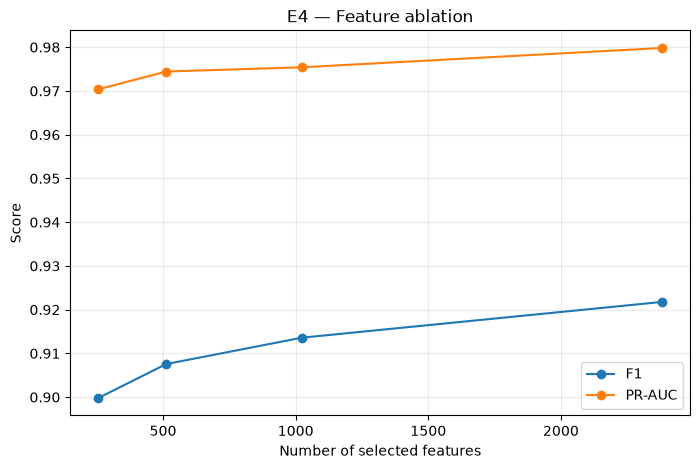

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(ablation_df["K"], ablation_df["F1"], marker="o", label="F1")
plt.plot(ablation_df["K"], ablation_df["PR_AUC"], marker="o", label="PR-AUC")
plt.xlabel("Number of selected features")
plt.ylabel("Score")
plt.title("E4 — Feature ablation")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

## 2.13. E4 — Threshold tuning

Threshold `0.5` không phải lúc nào cũng tối ưu.

Threshold chỉ được chọn trên **validation** bằng F1 tối đa. Sau khi khóa threshold mới chạy final test.

In [ ]:
from sklearn.metrics import precision_recall_curve

val_score = raw_score(best_model, X_bench_val)
precision, recall, thresholds = precision_recall_curve(y_bench_val, val_score)

f1 = 2*precision[:-1]*recall[:-1] / np.maximum(precision[:-1]+recall[:-1], 1e-12)
best_thr_idx = int(np.argmax(f1))
best_threshold = float(thresholds[best_thr_idx])

print("Default threshold:", 0.5)
print("Tuned threshold:", best_threshold)
print("Best validation F1:", f1[best_thr_idx])

display(pd.DataFrame([
    evaluate_binary(y_bench_val, val_score, 0.5),
    evaluate_binary(y_bench_val, val_score, best_threshold)
], index=["threshold_0.5","threshold_tuned"]).round(4))

Default threshold: 0.5
Tuned threshold: 0.5174000263214111
Best validation F1: 0.9028877939250295


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,FPR,TN,FP,FN,TP
threshold_0.5,0.9014,0.8962,0.9080,0.9021,0.9681,0.9706,0.1051,7159,841,736,7264
threshold_tuned,0.9027,0.9010,0.9048,0.9029,0.9681,0.9706,0.0994,7205,795,762,7238


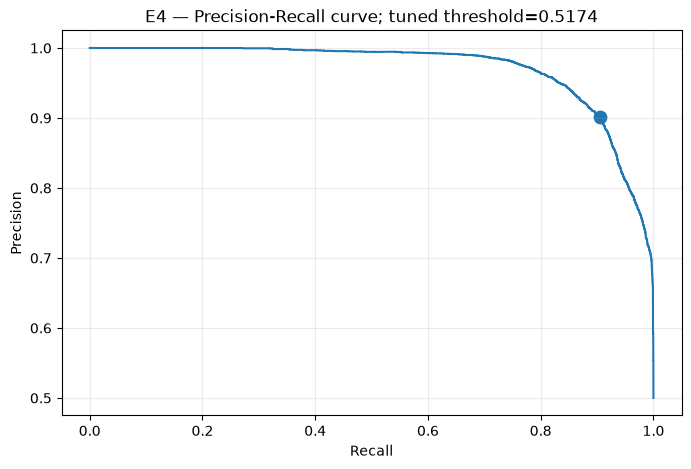

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(recall[:-1], precision[:-1])
plt.scatter(recall[best_thr_idx], precision[best_thr_idx], s=80)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"E4 — Precision-Recall curve; tuned threshold={best_threshold:.4f}")
plt.grid(alpha=0.25)
plt.show()

## 2.14. E5 — Explainable AI

Tree model: SHAP.

Model khác tree: permutation importance.

Ngoài top feature, notebook gom importance theo 9 nhóm EMBER để trả lời câu hỏi “model dựa nhiều vào loại đặc trưng nào?” mà không gán nhầm hashed dimension thành một API cụ thể.

In [ ]:
FEATURE_GROUPS = [
    ("histogram", 0, 256),
    ("byteentropy", 256, 512),
    ("section", 512, 767),
    ("imports", 767, 2047),
    ("exports", 2047, 2175),
    ("general", 2175, 2185),
    ("header", 2185, 2247),
    ("strings", 2247, 2351),
    ("datadirectories", 2351, 2381),
]

feature_names = []
for group, start, end in FEATURE_GROUPS:
    feature_names += [f"{group}_{i-start:04d}" for i in range(start, end)]

assert len(feature_names) == 2381
print(feature_names[:3], "...", feature_names[-3:])

['histogram_0000', 'histogram_0001', 'histogram_0002'] ... ['datadirectories_0027', 'datadirectories_0028', 'datadirectories_0029']


In [ ]:
import shap
from sklearn.inspection import permutation_importance
from catboost import CatBoostClassifier  # để SHAP TreeExplainer nhận diện CatBoost

final_est = best_model.steps[-1][1]
X_explain = X_bench_val[:min(500, len(X_bench_val))]

if isinstance(final_est, (LGBMClassifier, XGBClassifier, RandomForestClassifier, CatBoostClassifier)):
    X_trans = X_explain
    for _, step in best_model.steps[:-1]:
        X_trans = step.transform(X_trans)

    explainer = shap.TreeExplainer(final_est)
    shap_values = explainer.shap_values(X_trans)

    if isinstance(shap_values, list):
        shap_arr = np.asarray(shap_values[-1])
    else:
        shap_arr = np.asarray(shap_values)
    if shap_arr.ndim == 3:
        shap_arr = shap_arr[:, :, -1]

    mean_abs = np.mean(np.abs(shap_arr), axis=0)

    selected_mask = best_model.named_steps["variance"].get_support()
    after_var_names = np.asarray(feature_names)[selected_mask]
    selected_names = after_var_names[best_model.named_steps["select"].get_support()]

    top = np.argsort(mean_abs)[-20:][::-1]
    shap_df = pd.DataFrame({
        "feature": selected_names[top],
        "mean_abs_shap": mean_abs[top]
    })
    display(shap_df)

    plt.figure(figsize=(9,6))
    plt.barh(shap_df["feature"][::-1], shap_df["mean_abs_shap"][::-1])
    plt.xlabel("mean(|SHAP|)")
    plt.title("E5 — Top features")
    plt.tight_layout()
    plt.show()
else:
    pi = permutation_importance(
        best_model, X_explain, y_bench_val[:len(X_explain)],
        n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1, scoring="f1"
    )
    top = np.argsort(pi.importances_mean)[-20:][::-1]
    display(pd.DataFrame({
        "feature_index": top,
        "importance_mean": pi.importances_mean[top],
        "importance_std": pi.importances_std[top]
    }))

,feature_index,importance_mean,importance_std
0,930,0.018300,0.004868
1,623,0.009117,0.004850
2,692,0.008796,0.000630
3,1060,0.008633,0.001774
4,511,0.008046,0.001620
5,173,0.007625,0.000198
6,640,0.007585,0.003704
7,389,0.006617,0.002237
8,4,0.006616,0.003175
9,498,0.006036,0.001025


In [ ]:
if isinstance(final_est, (LGBMClassifier, XGBClassifier, RandomForestClassifier, CatBoostClassifier)):
    full_imp = np.zeros(N_FEATURES, dtype=float)
    after_var_idx = np.flatnonzero(best_model.named_steps["variance"].get_support())
    selected_idx = after_var_idx[best_model.named_steps["select"].get_support()]
    full_imp[selected_idx] = mean_abs

    rows = []
    for group, start, end in FEATURE_GROUPS:
        rows.append({
            "group": group,
            "mean_abs_importance": float(np.mean(np.abs(full_imp[start:end])))
        })

    group_df = pd.DataFrame(rows).sort_values("mean_abs_importance", ascending=False)
    display(group_df.round(6))

    plt.figure(figsize=(9,5))
    plt.barh(group_df["group"][::-1], group_df["mean_abs_importance"][::-1])
    plt.xlabel("Mean absolute importance")
    plt.title("E5 — Importance by EMBER feature group")
    plt.tight_layout()
    plt.show()

## 2.15. E6 — Temporal generalization

Train trên phần xuất hiện sớm hơn và test trên phần xuất hiện muộn hơn.

Nếu metric giảm, không được tự động kết luận model “sai”; cần xem thêm feature drift, family drift, packing/obfuscation và thay đổi threat landscape.

In [ ]:
temporal_model = Pipeline([
    ("variance", VarianceThreshold(0.0)),
    ("select", SelectKBest(f_classif, k=min(FEATURE_SELECTION_K, N_FEATURES))),
    ("model", LGBMClassifier(
        n_estimators=500, learning_rate=0.05, num_leaves=63,
        subsample=0.8, colsample_bytree=0.8,
        n_jobs=-1, random_state=RANDOM_STATE, verbosity=-1
    ))
])

temp_train_idx = balanced_indices_from_positions(
    train_idx_global, y_train_temporal,
    min(FINAL_MAX_PER_CLASS, 30_000), RANDOM_STATE
)
temp_val_idx = balanced_indices_from_positions(
    val_idx_global, y_val_temporal,
    min(max(5_000, BENCHMARK_VAL_PER_CLASS), 10_000), RANDOM_STATE
)

X_temp_train = np.asarray(X_train_mm[temp_train_idx])
y_temp_train = np.asarray(y_train_mm[temp_train_idx]).astype(int)
X_temp_val = np.asarray(X_train_mm[temp_val_idx])
y_temp_val = np.asarray(y_train_mm[temp_val_idx]).astype(int)

t0 = time.perf_counter()
temporal_model.fit(X_temp_train, y_temp_train)
print("Fit seconds:", time.perf_counter()-t0)

temp_score = temporal_model.predict_proba(X_temp_val)[:,1]
display(pd.DataFrame([
    evaluate_binary(y_temp_val, temp_score, best_threshold)
], index=["Temporal validation"]).round(4))

Fit seconds: 64.54913501599913


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,FPR,TN,FP,FN,TP
Temporal validation,0.9094,0.9078,0.9115,0.9096,0.9678,0.9714,0.0926,7259,741,708,7292


## 2.16. E6 — Final EMBER test

Test chính thức chỉ dùng sau khi model và threshold đã được khóa.

Dự đoán theo chunk để không nạp toàn bộ test vào RAM.

In [ ]:
def predict_scores_chunked(model, X_mm, chunk_size=10000):
    scores = np.empty(len(X_mm), dtype=np.float32)
    for start in range(0, len(X_mm), chunk_size):
        end = min(start + chunk_size, len(X_mm))
        scores[start:end] = raw_score(model, np.asarray(X_mm[start:end]))
    return scores

t0 = time.perf_counter()
test_scores = predict_scores_chunked(best_model, X_test_mm, FINAL_TEST_CHUNK)
test_infer_s = time.perf_counter() - t0

y_test_np = np.asarray(y_test_mm).astype(int)
final_test_metrics = evaluate_binary(y_test_np, test_scores, best_threshold)
final_test_metrics["Inference_seconds"] = test_infer_s
final_test_metrics["Inference_ms_per_sample"] = 1000*test_infer_s/len(y_test_np)

display(pd.DataFrame([final_test_metrics],
                     index=[f"{best_model_name} — EMBER official test"]).round(4))

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,FPR,TN,FP,FN,TP,Inference_seconds,Inference_ms_per_sample
AutoGluon — EMBER official test,0.9091,0.8915,0.9317,0.9111,0.9709,0.9728,0.1134,88659,11341,6830,93170,95.0162,0.4751


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


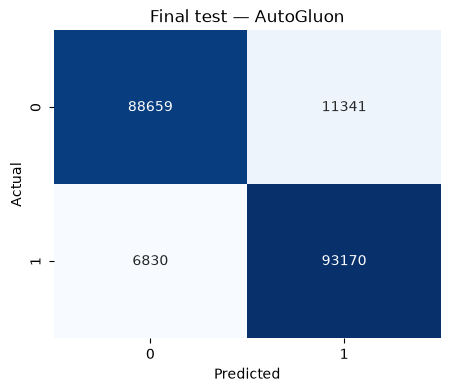

In [ ]:
cm = confusion_matrix(y_test_np, (test_scores >= best_threshold).astype(int), labels=[0,1])
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"Final test — {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
from sklearn.metrics import roc_curve

fpr_curve, tpr_curve, roc_thresholds = roc_curve(y_test_np, test_scores)

def detection_rate_at_fpr(target_fpr):
    idx = np.searchsorted(fpr_curve, target_fpr, side="right") - 1
    idx = max(idx, 0)
    return tpr_curve[idx], roc_thresholds[idx], fpr_curve[idx]

print(f"Candidate: {best_model_name}\n")
for target in [0.001, 0.01]:
    recall_at, thr_at, actual_fpr = detection_rate_at_fpr(target)
    print(f"Detection rate @ FPR<={target*100:.1f}%: {recall_at*100:.2f}%  "
          f"(threshold={thr_at:.4f}, FPR thực tế đạt được={actual_fpr*100:.3f}%)")

print("\nSo với EMBER paper gốc (LightGBM, Anderson & Roth 2018, train full 600K mẫu, full 2381 feature):")
print("  - Detection rate @ FPR<0.1%:  92.99% (paper)")
print("  - Detection rate @ FPR<1%:    98.20% (paper)")
print("\nLưu ý: paper gốc train trên TOÀN BỘ 600.000 mẫu labeled với full 2.381 feature —")
print("không giới hạn benchmark train/val K=256 như notebook này. Chênh lệch lớn ở đây")
print("phần lớn đến từ 2 điểm đó, không phải do thuật toán yếu hơn (xem ablation 2.12).")

Candidate: AutoGluon

Detection rate @ FPR<=0.1%: 35.38%  (threshold=0.9932, FPR thực tế đạt được=0.100%)
Detection rate @ FPR<=1.0%: 69.34%  (threshold=0.9494, FPR thực tế đạt được=1.000%)

So với EMBER paper gốc (LightGBM, Anderson & Roth 2018, train full 600K mẫu, full 2381 feature):
  - Detection rate @ FPR<0.1%:  92.99% (paper)
  - Detection rate @ FPR<1%:    98.20% (paper)

Lưu ý: paper gốc train trên TOÀN BỘ 600.000 mẫu labeled với full 2.381 feature —
không giới hạn benchmark train/val K=256 như notebook này. Chênh lệch lớn ở đây
phần lớn đến từ 2 điểm đó, không phải do thuật toán yếu hơn (xem ablation 2.12).


## 2.17. E7 — External validation hook

Có thể đưa BODMAS hoặc dataset PE khác vào cùng không gian 2.381 feature.

Notebook không tự tải dataset ngoài vì cấu trúc phát hành/điều khoản có thể thay đổi. Chỉ cần chuẩn hóa thành:

- `X_external.shape = (N, 2381)`
- `y_external ∈ {0,1}`

Sau đó dùng cell dưới.

In [ ]:
def evaluate_external_dataset(model, X_external, y_external, threshold=0.5, name="External"):
    X_external = np.asarray(X_external, dtype=np.float32)
    y_external = np.asarray(y_external).astype(int)

    if X_external.shape[1] != N_FEATURES:
        raise ValueError(f"Expected {N_FEATURES} features, got {X_external.shape[1]}")

    score = raw_score(model, X_external)
    return pd.DataFrame(
        [evaluate_binary(y_external, score, threshold)],
        index=[name]
    )

# Example:
# X_external = np.load("/content/external_X.npy", mmap_mode="r")
# y_external = np.load("/content/external_y.npy")
# display(evaluate_external_dataset(best_model, X_external, y_external, best_threshold, "BODMAS"))

## 2.18. E8 — Phân tích tĩnh PE mới

Pipeline triển khai:

**PE → bytes → EMBER PEFeatureExtractor → vector 2.381 → model → score → threshold → kết luận.**

Chỉ đọc bytes, không tạo process và không chạy file.

In [ ]:
import sys, numpy as np

# Compatibility cho source EMBER cũ dùng np.int
if not hasattr(np, "int"):
    np.int = int

sys.path.insert(0, "/content/ember_src")

try:
    import lief
    from ember.features import PEFeatureExtractor
    print("LIEF:", lief.__version__)
    extractor = PEFeatureExtractor(
        feature_version=FEATURE_VERSION,
        print_feature_warning=True
    )
    print("Extractor dimension:", extractor.dim)
except Exception as e:
    extractor = None
    print("Extractor initialization failed:", repr(e))

LIEF: 1.0.0-d05b3499b
Extractor dimension: 2381


In [ ]:
def static_extract_pe(file_path):
    file_path = Path(file_path)
    data = file_path.read_bytes()

    if data[:2] != b"MZ":
        raise ValueError("Not a PE candidate: missing MZ signature.")
    if extractor is None:
        raise RuntimeError("PEFeatureExtractor is not available.")

    vector = np.asarray(extractor.feature_vector(data), dtype=np.float32)
    if vector.shape != (N_FEATURES,):
        raise ValueError(f"Expected {(N_FEATURES,)}, got {vector.shape}")
    return vector

def predict_pe_file(file_path):
    vector = static_extract_pe(file_path)
    score = float(raw_score(best_model, vector.reshape(1,-1))[0])
    return {
        "file": str(file_path),
        "size_bytes": Path(file_path).stat().st_size,
        "malware_score": score,
        "threshold": float(best_threshold),
        "prediction": "MALICIOUS" if score >= best_threshold else "BENIGN"
    }

### Upload PE để demo

Chỉ upload file mà nhóm có quyền phân tích. Với malware thật, không dùng Colab thông thường như một sandbox.

In [ ]:
# Uncomment khi cần:
#
# from google.colab import files
# uploaded = files.upload()
# pe_path = next(iter(uploaded.keys()))
# print(predict_pe_file(pe_path))

## 2.19. E8 — Thông tin tĩnh hiển thị trên app

Ngoài score AI, ứng dụng nên hiển thị SHA-256, kích thước, section/import/export/string statistics.

Không nên tự động gọi một API import cụ thể là “độc hại”; đây chỉ là evidence tĩnh.

In [ ]:
def sha256_bytes(data):
    return __import__("hashlib").sha256(data).hexdigest()

def pe_static_summary(file_path):
    file_path = Path(file_path)
    data = file_path.read_bytes()
    if data[:2] != b"MZ":
        raise ValueError("Not a PE candidate.")

    result = {
        "file": file_path.name,
        "size_bytes": len(data),
        "sha256": sha256_bytes(data),
        "signature": "MZ"
    }

    if extractor is not None:
        raw = extractor.raw_features(data)
        result["sections"] = len(raw.get("section", {}).get("sections", []))
        result["imports"] = sum(len(v) for v in raw.get("imports", {}).values())
        result["exports"] = len(raw.get("exports", []))
        result["num_strings"] = raw.get("strings", {}).get("numstrings", 0)
        result["string_entropy"] = raw.get("strings", {}).get("entropy", 0.0)

    return result

## 2.20. E9 — Lưu model + threshold + schema

Không chỉ lưu model. Artifact phải chứa:

- model;
- threshold;
- feature version;
- số feature;
- K feature;
- seed;
- benchmark metrics;
- final test metrics;
- package versions.

In [ ]:
import joblib, json, platform
import numpy as np # Import numpy if not already imported in this cell

def convert_numpy_types(obj):
    if isinstance(obj, np.integer):
        return int(obj)
    elif isinstance(obj, np.floating):
        return float(obj)
    elif isinstance(obj, dict):
        return {k: convert_numpy_types(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [convert_numpy_types(elem) for elem in obj]
    return obj

# Convert numpy types in final_test_metrics before serialization
final_test_metrics_converted = convert_numpy_types(final_test_metrics)

artifact = {
    "model": best_model,
    "threshold": float(best_threshold),
    "feature_version": FEATURE_VERSION,
    "n_features": N_FEATURES,
    "feature_selection_k": FEATURE_SELECTION_K,
    "random_state": RANDOM_STATE,
    "selected_model": best_model_name,
    "benchmark_metrics": benchmark_df.reset_index().to_dict(orient="records"),
    "final_test_metrics": final_test_metrics_converted, # Use the converted dictionary here
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
    "lightgbm": lightgbm.__version__,
    "xgboost": xgboost.__version__
}

model_path = RESULT_ROOT / "klcn04_malware_model.joblib"
joblib.dump(artifact, model_path)

benchmark_df.to_csv(RESULT_ROOT / "benchmark_results.csv")
with open(RESULT_ROOT / "final_test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(final_test_metrics_converted, f, ensure_ascii=False, indent=2) # Use the converted dictionary here

print("Saved:", model_path)

Saved: /content/klcn04_results/klcn04_malware_model.joblib


## 2.21. E9 — Bảng kết quả cho Chương 3

In [ ]:
chapter3_table = benchmark_df.reset_index()[[
    "Model","Accuracy","Precision","Recall","F1","ROC_AUC",
    "PR_AUC","FPR","Fit_seconds","Inference_ms_per_sample"
]].sort_values(["F1","PR_AUC"], ascending=False)

display(chapter3_table.round(4))
chapter3_table.to_csv(RESULT_ROOT / "chapter3_model_comparison.csv", index=False)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,FPR,Fit_seconds,Inference_ms_per_sample
0,AutoGluon,0.9014,0.8962,0.9080,0.9021,0.9681,0.9706,0.1051,313.5796,0.3645
1,LightGBM+PseudoLabel,0.9004,0.8931,0.9096,0.9013,0.9705,0.9723,0.1089,59.4529,0.1166
2,HillClimb-Blend,0.9002,0.8941,0.9079,0.9009,0.9703,0.9726,0.1075,0.0000,0.0000
3,HillClimb-Blend,0.9002,0.8941,0.9079,0.9009,0.9703,0.9726,0.1075,0.0000,0.0000
4,LightGBM,0.9001,0.8960,0.9054,0.9006,0.9688,0.9716,0.1051,44.3026,0.0851
5,Stacking-LogReg,0.8991,0.8939,0.9056,0.8997,0.9696,0.9716,0.1075,1114.5410,0.1716
6,XGBoost,0.8968,0.8885,0.9075,0.8979,0.9682,0.9706,0.1139,66.3443,0.0370
7,CatBoost,0.8906,0.8818,0.9021,0.8919,0.9627,0.9644,0.1209,145.5479,0.0224
8,SVM,0.8862,0.8818,0.8921,0.8869,0.9567,0.9534,0.1196,1133.3176,4.7150
9,RandomForest,0.8843,0.8737,0.8985,0.8859,0.9620,0.9623,0.1299,133.9736,0.0967


## 2.22. E9 — Summary tự động

**Không điền số trước khi chạy notebook.**

In [ ]:
summary_text = f"""
ATTT-KLCN04 — CHAPTER 2 EXPERIMENT SUMMARY

Dataset:
- EMBER 2018 feature version {FEATURE_VERSION}
- Original feature dimension: {N_FEATURES}
- Benchmark train per class: {BENCHMARK_TRAIN_PER_CLASS}
- Benchmark validation per class: {BENCHMARK_VAL_PER_CLASS}

Selected candidate:
- Model: {best_model_name}
- Threshold tuned on validation: {best_threshold:.6f}

Benchmark:
{benchmark_df.round(4).to_string()}

Final EMBER test:
{pd.Series(final_test_metrics).round(6).to_string()}

IMPORTANT:
- These are experimental outputs of this notebook.
- Do not claim them before actually running the notebook.
- Report dataset size, split, feature version, preprocessing, threshold and hardware.
"""

(RESULT_ROOT / "chapter2_summary.txt").write_text(summary_text, encoding="utf-8")
print(summary_text)


ATTT-KLCN04 — CHAPTER 2 EXPERIMENT SUMMARY

Dataset:
- EMBER 2018 feature version 2
- Original feature dimension: 2381
- Benchmark train per class: 20000
- Benchmark validation per class: 8000

Selected candidate:
- Model: AutoGluon
- Threshold tuned on validation: 0.517400

Benchmark:
                        Accuracy  Precision  Recall      F1  ROC_AUC  PR_AUC     FPR    TN    FP    FN    TP  Fit_seconds  Inference_seconds  Inference_ms_per_sample
Model                                                                                                                                                                
AutoGluon                 0.9014     0.8962  0.9080  0.9021   0.9681  0.9706  0.1051  7159   841   736  7264     313.5796             5.8313                   0.3645
LightGBM+PseudoLabel      0.9004     0.8931  0.9096  0.9013   0.9705  0.9723  0.1089  7129   871   723  7277      59.4529             1.8649                   0.1166
HillClimb-Blend           0.9002     0.8941  0.9

## 2.23. E10 — Tạo Streamlit app tối giản

App chỉ làm:

**Upload PE → static feature extraction → model score → result.**

Không có chức năng execute binary.

In [ ]:
APP_CODE = r"""
import streamlit as st
from pathlib import Path
import joblib
import hashlib
import numpy as np
import sys

st.set_page_config(page_title="KLCN04 Windows Malware Detector", layout="wide")
st.title("Windows PE Static Malware Detector")
st.caption("Static analysis only — uploaded PE is not executed.")

artifact = joblib.load("klcn04_malware_model.joblib")
model = artifact["model"]
threshold = artifact["threshold"]

if not hasattr(np, "int"):
    np.int = int

sys.path.insert(0, "ember_src")
from ember.features import PEFeatureExtractor
extractor = PEFeatureExtractor(feature_version=artifact["feature_version"])

uploaded = st.file_uploader("Upload Windows PE (.exe/.dll/.sys)", type=["exe","dll","sys"])

if uploaded is not None:
    data = uploaded.getvalue()

    if data[:2] != b"MZ":
        st.error("Missing PE/DOS MZ signature.")
        st.stop()

    sha256 = hashlib.sha256(data).hexdigest()
    vector = np.asarray(extractor.feature_vector(data), dtype=np.float32)
    score = float(model.predict_proba(vector.reshape(1,-1))[:,1][0])

    c1, c2, c3 = st.columns(3)
    c1.metric("File size", f"{len(data):,} bytes")
    c2.metric("SHA-256", sha256[:16] + "...")
    c3.metric("Malware score", f"{score*100:.2f}%")

    if score >= threshold:
        st.error(f"MALICIOUS — threshold={threshold:.4f}")
    else:
        st.success(f"BENIGN — threshold={threshold:.4f}")

    st.info("ML score from static PE features; not a substitute for analyst/sandbox confirmation.")
"""

app_path = RESULT_ROOT / "app.py"
app_path.write_text(APP_CODE, encoding="utf-8")
print("Created:", app_path)

Created: /content/klcn04_results/app.py


# 2.24. Troubleshooting

### Dataset quá lớn
Giữ `DEMO_MODE=True` để kiểm tra pipeline trước; sau đó chuyển `False` cho run chính.

### RAM
Không chạy `np.array(X_train_mm)` cho toàn bộ dataset. Notebook dùng memmap.

### SVM quá chậm
Giảm `BENCHMARK_TRAIN_PER_CLASS` nhưng giữ cùng budget cho tất cả model trong benchmark.

### LIEF lỗi
Kiểm tra `lief.__version__` và `extractor.dim`. Không đưa vector khác 2.381 chiều vào model.

### SHAP lỗi
Dùng permutation importance fallback, không đoán cách reshape SHAP.

### Final test chậm
Dùng chunking; thay đổi `FINAL_TEST_CHUNK` chỉ thay đổi batch size.

# 2.25. Checklist trước khi đưa số liệu vào khóa luận

- [ ] SHA-256 dataset đã kiểm tra.
- [ ] Đúng EMBER feature version 2.
- [ ] Không dùng label `-1`.
- [ ] Train/validation/test rõ ràng.
- [ ] Không fit preprocessing trên test.
- [ ] RF, SVM, XGBoost, LightGBM, MLP cùng benchmark protocol.
- [ ] Accuracy / Precision / Recall / F1 / ROC-AUC / PR-AUC / FPR.
- [ ] Confusion matrix.
- [ ] Feature ablation.
- [ ] Threshold tuning trên validation.
- [ ] SHAP hoặc permutation importance.
- [ ] Temporal validation.
- [ ] Final test độc lập.
- [ ] Inference time.
- [ ] Model + threshold + feature schema được lưu.
- [ ] PE inference không execute file.
- [ ] Không tuyên bố 95–96% trước khi có kết quả thực nghiệm.

# 2.26. Mapping notebook → Chương 2 báo cáo

| Notebook | Báo cáo |
|---|---|
| E0 | 2.1 Môi trường thực nghiệm |
| E1 | 2.2 Dataset và kiểm tra dữ liệu |
| E2 | 2.3 Thiết kế train/validation/test |
| E3 | 2.4 Tiền xử lý và so sánh ML |
| E4 | 2.5 Tối ưu feature + threshold |
| E5 | 2.6 Explainable AI |
| E6 | 2.7 Temporal generalization |
| E7 | 2.8 External validation |
| E8 | 2.9 Static PE inference |
| E9 | 2.10 Đóng gói model |
| E10 | 2.11 Ứng dụng Web |

**Quan trọng:** Notebook là thiết kế thực nghiệm. Các con số trong luận văn chỉ được lấy sau khi nhóm chạy thật.

# Tài liệu tham khảo chính

1. Anderson, H. S., & Roth, P. (2018). *EMBER: An Open Dataset for Training Static PE Malware Machine Learning Models*. https://arxiv.org/abs/1804.04637
2. Elastic / Endgame. *EMBER — Elastic Malware Benchmark for Empowering Researchers*. https://github.com/elastic/ember
3. EMBER 2018 dataset. https://ember.elastic.co/ember_dataset_2018_2.tar.bz2
4. Scikit-learn. https://scikit-learn.org/
5. XGBoost. https://xgboost.readthedocs.io/
6. LightGBM. https://lightgbm.readthedocs.io/
7. SHAP. https://shap.readthedocs.io/